# Insight
- The problem: Given data trace for the whole day of a device, can i predict if that device is an IoT or non-IoT?
- Data preprocessing steps:
    - Any devices that only have one trace file is dropped because they can't be splitted into training and validation fold
- Training and validation fold is splitted using Leave-One-Out approach
    - In each fold, for each device, pick one trace file for the validation, the rest will be placed in the training folds

- The reason for the misclassification is that:
    - Vector `(0,0)` get classfied as `0`, and this vector dominate the features belonging to these devices
        - Even though `(0,0)` associated with label 1 more (5000 vs 2000), `RandomUnderSampler` actually remove that dominant. <mark>What happen if we remove it?</mark>
            - Okay, without `RandomUnderSampler`, there is an imbalanced dataset, which make the model predict everything to be IoT. What if we add `classweight` to penalize wrong prediction on non-IoT class heavier?
                - After adding classweight, the same misclassification still happening, what if we drop those device?
                    - After dropping those devices, the accuracy increase significantly. Out of 5 folds, we usually get 3 folds with maximum accuracy, the rest usually get misclassified on `[74:c6:3b:29:d7:1d, e0:76:d0:33:bb:85]`
                - Okay, if we don't drop it, then what is the solution? <mark> can we extend the window so that the number of inactive window get smaller in those devices? Let's try</mark>
                    - I tried up to 11 hours window size. Something interesting appears. The accuracy does increase but we haven't reached 100%.
                    - I thought about increasing the window size more, but it would be irrational. Since we evaluate the device based on the trace of one day worth of trace, if our window size is about 12 hours, then we only have 2 sample for training and validation which is no different than random decision.
    - Nest Protect has a different problem. Its active window are still being predicted as non-IoT. <mark>We might need to add features?</mark>
        - We might need more information to be able to tell it apart. <mark>More features?</mark>
            - We have been only recording outgoing volume, what about incoming? <mark> Try that and it doesn't improve</mark>

# Meeting Note
## Do another sampler method
## We can skip inactive window while training and validating 
- <mark> Trying this first</mark>
- First observation:
    - Optimal window size: 2400, accuracy: 91%
    - The misclassified devices are all false positive, which seems like an imbalanced dataset
    - The window size vs performance plot looks messy, looks pretty much like random -> <mark>might be mixed signal between iot device and non-iot device?</mark>
```bash
mac: 08:21:ef:3b:fc:e3, device_name: Samsung Galaxy Tab, is_iot_device: 0, vendor: nan
mac: b4:ce:f6:a7:a3:c2, device_name: Android Phone, is_iot_device: 0, vendor: nan
mac: 40:f3:08:ff:1e:da, device_name: Android Phone, is_iot_device: 0, vendor: nan
mac: d0:a6:37:df:a1:e1, device_name: IPhone, is_iot_device: 0, vendor: nan
```
- Is it because of camera being in the dataset?
    - Looks like it is, when I drop camera from the dataset, the model reach it peaks at `100 seconds window`
        - It got 100% accuracy in three folds. One fold, it misclassifies `b4:ce:f6:a7:a3:c2`, and `74:6a:89:00:2e:25` for the others.
            - Reason: [Validation detail](./imgs/50-50-decision.png)
                - For `b4:ce:f6:a7:a3:c2`, the model is 50/50 on this decision
                - For `74:6a:89:00:2e:25`, same issue we had initially, this produces too less window for us to vote efficiently
    - Also looking at the scatter plot for this window, the data looks much more separable [Distribution Plots](./imgs/100s-window-distribution-plot.png)
- What if we also drop the gateway?
    - We drop it and got 100% accuracy!! for 120 seconds window
- What if we drop gateway and keep camera?
    - Some devices can not be classified correctly because of following reasons ([40s window dropping gateway performance](./imgs/40s-window-drop-gateway.png)):
        - 50/50 scenario
        - Some IoT devices (blood pressure) has too small number of active windows to be considered for majority voting
- Now that we know the full labels of the dataset? What if we rerun the experiment?
    - For some reason, the list of devices mentioned in the paper cannot be found in the dataset
## Another feature can be last inactive time
## May be model the labels into: non-IoT, IoT, and resource-constraint IoT
## Look into graph model kind of thing

In [1]:
import sys
from pathlib import Path

package_root = str(Path.cwd().parent)
if package_root not in sys.path:
    sys.path.append(package_root)

In [2]:
from __future__ import annotations
import pandas as pd 
import json
from typing import Dict, List, Tuple, Set
from pathlib import Path
from collections.abc import Iterable
import matplotlib.pyplot as plt
import seaborn as sns
import os 
import time
import re
import numpy as np
from copy import deepcopy
from datetime import datetime
from typing import Any
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

In [3]:
pd.set_option("display.max_colwidth", None)

In [23]:
DATASET_FOLDER = "../../../dataset/processed-data"
DEVICE_MAPPING_FOLDER = DATASET_FOLDER + "/device-mapping"
INPUT_FOLDER = DATASET_FOLDER + "/input-data"
DATASET1 = "dataset1"
DATASET2 = "dataset2"
EXTRACTED_DATA_FOLDER = DATASET1 + "/all_traffic.parquet"
DEVICE_TO_BE_INCLUDE = DATASET1 + "/device_to_be_include.json"
PERFORMANCE_EXPORT_FOLDER = "./performance"

In [5]:
MAPPING_LIST_1 = f"{DEVICE_MAPPING_FOLDER}/{DATASET1}/list_of_devices_processed.csv"
MAPPING_LIST_2 = f"{DEVICE_MAPPING_FOLDER}/{DATASET2}/list_of_devices_processed.csv"
INPUT_1 = f"{INPUT_FOLDER}/{DATASET1}"
INPUT_2 = f"{INPUT_FOLDER}/{DATASET2}"

In [6]:
device_dict_1 = {}
with open(DEVICE_TO_BE_INCLUDE, "r") as f:
    device_dict_1= json.load(f)
device_dict_1

{'d0:52:a8:00:67:5e': {'device_name': 'Smart Things',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'hub',
  'vendor': 'Samsung SmartThings'},
 '44:65:0d:56:cc:d3': {'device_name': 'Amazon Echo',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'smart speaker',
  'vendor': 'Amazon'},
 '70:ee:50:18:34:43': {'device_name': 'Netatmo Welcome',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Netatmo'},
 'f4:f2:6d:93:51:f1': {'device_name': 'TP-Link Day Night Cloud camera',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'TP-Link'},
 '00:16:6c:ab:6b:88': {'device_name': 'Samsung SmartCam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Samsung'},
 '30:8c:fb:2f:e4:b2': {'device_name': 'Dropcam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Dropcam'},
 '00:62:6e:51:27:2e': {'device_name': 'Insteon Camera Wired',
  'ip_address': 

In [7]:
all_data = pd.read_parquet(EXTRACTED_DATA_FOLDER)

In [8]:
all_data.head(5)

,frame.time_epoch,frame.len,eth.src,eth.dst,capture_id
0,1.474553e+09,70,18:b7:9e:02:20:44,14:cc:20:51:33:ea,16-09-23
1,1.474553e+09,66,18:b7:9e:02:20:44,14:cc:20:51:33:ea,16-09-23
2,1.474553e+09,66,14:cc:20:51:33:ea,30:8c:fb:2f:e4:b2,16-09-23
3,1.474553e+09,60,d0:52:a8:00:67:5e,14:cc:20:51:33:ea,16-09-23
4,1.474553e+09,98,14:cc:20:51:33:ea,70:ee:50:18:34:43,16-09-23


In [9]:
process_df = all_data.copy()

In [10]:
WINDOW_SECONDS = 60
ALL_FEATURES = [
    "outgoing_packet_count",
    "outgoing_total_bytes",
    "outgoing_idle_time",
]
LABEL_COLUMN = "is_iot_device"
KSPLITS=5
RANDOM_SEED=42

In [11]:
def get_all_devices(list_of_devices: List[str]) -> Set[str]:
    return set(list_of_devices)
def drop_router(list_of_devices: List[str]) -> Set[str]:
    router_devices = set(["14:cc:20:51:33:ea"])
    return set(list_of_devices) - router_devices
def drop_router_and_hub(list_of_devices: List[str]) -> Set[str]:
    router_devices = set(["14:cc:20:51:33:ea"])
    hub_devices = set(["d0:52:a8:00:67:5e","44:65:0d:56:cc:d3"])
    return set(list_of_devices) - router_devices - hub_devices
def drop_router_and_camera(list_of_devices: List[str]) -> Set[str]:
    router_devices = set(["14:cc:20:51:33:ea"])
    camera_devices = set(["70:ee:50:18:34:43","30:8c:fb:2f:e4:b2","00:16:6c:ab:6b:88","f4:f2:6d:93:51:f1","00:62:6e:51:27:2e"])
    return set(list_of_devices) - router_devices - camera_devices

dropping_strategies = {
    "no_dropping": get_all_devices,
    "drop_router": drop_router,
    "drop_router_and_hub": drop_router_and_hub,
    "drop_router_and_camera": drop_router_and_camera,
}

In [12]:
def label_2_class(features: pd.DataFrame, device_mapping: Dict[str, Dict[str,str]]) -> pd.DataFrame:
    unknown_macs = set(features["mac"]) - set(device_mapping)
    if unknown_macs:
        raise KeyError(
            f"MAC addresses not found in device_mapping: {unknown_macs}"
        )
    res = features.copy()
    res["is_iot_device"] = res["mac"].map(
        lambda x: device_mapping[x]["is_iot_device"]
    )
    res["device_type"] = res["mac"].map(
        lambda x: device_mapping[x]["device_type"]
    )
    res["vendor"] = res["mac"].map(
        lambda x: device_mapping[x]["vendor"]
    )

    return res
def label_3_class_health_care_device_type_3(features: pd.DataFrame, device_mapping: Dict[str, Dict[str,str]]) -> pd.DataFrame:
    unknown_macs = set(features["mac"]) - set(device_mapping)
    if unknown_macs:
        raise KeyError(
            f"MAC addresses not found in device_mapping: {unknown_macs}"
        )
    device_mapping_copy = deepcopy(device_mapping)
    health_monitor_devices = set(["74:6a:89:00:2e:25","18:b4:30:25:be:e4","00:24:e4:1b:6f:96"])
    for mac in device_mapping_copy:
        if device_mapping_copy[mac]["is_iot_device"] == 0:
            device_mapping_copy[mac]["is_iot_device"] = 1
        else:
            if mac in health_monitor_devices:
                device_mapping_copy[mac]["is_iot_device"] = 3
            else:
                device_mapping_copy[mac]["is_iot_device"] = 2
    res = features.copy()
    res["is_iot_device"] = res["mac"].map(
        lambda x: device_mapping_copy[x]["is_iot_device"]
    )
    res["device_type"] = res["mac"].map(
        lambda x: device_mapping_copy[x]["device_type"]
    )
    res["vendor"] = res["mac"].map(
        lambda x: device_mapping_copy[x]["vendor"]
    )

    return res
def label_3_class_camera_device_type_3(features: pd.DataFrame, device_mapping: Dict[str, Dict[str,str]]) -> pd.DataFrame:
    unknown_macs = set(features["mac"]) - set(device_mapping)
    if unknown_macs:
        raise KeyError(
            f"MAC addresses not found in device_mapping: {unknown_macs}"
        )
    device_mapping_copy = deepcopy(device_mapping)
    camera_set = set(["30:8c:fb:b6:ea:45", "00:62:6e:51:27:2e", "e8:ab:fa:19:de:4f", "30:8c:fb:2f:e4:b2", "00:16:6c:ab:6b:88","f4:f2:6d:93:51:f1","70:ee:50:18:34:43"])
    for mac in device_mapping_copy:
        if device_mapping_copy[mac]["is_iot_device"] == 0:
            device_mapping_copy[mac]["is_iot_device"] = 1
        else:
            if mac in camera_set:
                device_mapping_copy[mac]["is_iot_device"] = 3
            else:
                device_mapping_copy[mac]["is_iot_device"] = 2
    res = features.copy()
    res["is_iot_device"] = res["mac"].map(
        lambda x: device_mapping_copy[x]["is_iot_device"]
    )
    res["device_type"] = res["mac"].map(
        lambda x: device_mapping_copy[x]["device_type"]
    )
    res["vendor"] = res["mac"].map(
        lambda x: device_mapping_copy[x]["vendor"]
    )

    return res
def label_4_class_camera_and_health_care(features: pd.DataFrame, device_mapping: Dict[str, Dict[str,str]]) -> pd.DataFrame:
    unknown_macs = set(features["mac"]) - set(device_mapping)
    if unknown_macs:
        raise KeyError(
            f"MAC addresses not found in device_mapping: {unknown_macs}"
        )
    device_mapping_copy = deepcopy(device_mapping)
    health_monitor_devices = set(["74:6a:89:00:2e:25","18:b4:30:25:be:e4","00:24:e4:1b:6f:96"])
    camera_set = set(["30:8c:fb:b6:ea:45", "00:62:6e:51:27:2e", "e8:ab:fa:19:de:4f", "30:8c:fb:2f:e4:b2", "00:16:6c:ab:6b:88","f4:f2:6d:93:51:f1","70:ee:50:18:34:43"])
    for mac in device_mapping_copy:
        if device_mapping_copy[mac]["is_iot_device"] == 0:
            device_mapping_copy[mac]["is_iot_device"] = 1
        else:
            if mac in health_monitor_devices:
                device_mapping_copy[mac]["is_iot_device"] = 3
            elif mac in camera_set:
                device_mapping_copy[mac]["is_iot_device"] = 4
            else:
                device_mapping_copy[mac]["is_iot_device"] = 2
    
    
    res = features.copy()
    res["is_iot_device"] = res["mac"].map(
        lambda x: device_mapping_copy[x]["is_iot_device"]
    )
    res["device_type"] = res["mac"].map(
        lambda x: device_mapping_copy[x]["device_type"]
    )
    res["vendor"] = res["mac"].map(
        lambda x: device_mapping_copy[x]["vendor"]
    )

    return res

labeling_strategies = {
    "nonIot-vs-iot": (label_2_class, [0,1]),
    "nonIot-vs-iot-vs-iotHealthCare": (label_3_class_health_care_device_type_3, [1,2,3]),
    "nonIot-vs-iot-vs-iotCamera": (label_3_class_camera_device_type_3, [1,2,3]),
    "nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera": (label_4_class_camera_and_health_care, [1,2,3,4])
}   

In [13]:
def build_feature(
    raw_df: pd.DataFrame,
    device_to_be_include: set,
    window: int = WINDOW_SECONDS
) -> pd.DataFrame:

    if window <= 0:
        raise ValueError("window must be greater than 0")

    all_features = []

    df = raw_df.copy()

    for capture_id, capture_df in df.groupby(
        "capture_id",
        sort=False,
        observed=True,
    ):
        capture_df = capture_df.copy()

        devices = capture_df["eth.src"].dropna().unique()

        devices = np.array([
            device
            for device in devices
            if device in device_to_be_include
        ])

        if len(devices) == 0:
            continue

        capture_start = capture_df["frame.time_epoch"].min()

        capture_df["window"] = (
            (capture_df["frame.time_epoch"] - capture_start) // window
        ).astype("int32")

        features = (
            capture_df[
                capture_df["eth.src"].isin(devices)
            ]
            .groupby(
                ["window", "eth.src"],
                sort=False,
                observed=True,
            )
            .agg(
                outgoing_packet_count=("frame.len", "size"),
                outgoing_total_bytes=("frame.len", "sum"),
                first_timestamp=("frame.time_epoch", "min"),
                last_timestamp=("frame.time_epoch", "max"),
            )
            .reset_index()
        )

        features = features.sort_values(
            ["eth.src", "window"]
        )

        features["previous_last_timestamp"] = (
            features
            .groupby(
                "eth.src",
                observed=True
            )["last_timestamp"]
            .shift(1)
        )

        features["outgoing_idle_time"] = np.where(
            features["previous_last_timestamp"].isna(),
            features["first_timestamp"] - capture_start,
            features["first_timestamp"] - features["previous_last_timestamp"]
        )

        features["capture_id"] = capture_id

        features = features[
            [
                "capture_id",
                "window",
                "eth.src",
                "outgoing_packet_count",
                "outgoing_total_bytes",
                "outgoing_idle_time",
            ]
        ]

        all_features.append(features)

    if not all_features:
        return pd.DataFrame(
            columns=[
                "capture_id",
                "window",
                "eth.src",
                "outgoing_packet_count",
                "outgoing_total_bytes",
                "outgoing_idle_time",
            ]
        )

    result = pd.concat(
        all_features,
        ignore_index=True,
    )

    result["outgoing_packet_count"] = result["outgoing_packet_count"].astype("int64")
    result["outgoing_total_bytes"] = result["outgoing_total_bytes"].astype("int64")
    result["outgoing_idle_time"] = result["outgoing_idle_time"].astype("float64")
    result = result.rename(columns={"eth.src": "mac"})

    return result[
        [
            "capture_id",
            "window",
            "mac",
            "outgoing_packet_count",
            "outgoing_total_bytes",
            "outgoing_idle_time",
        ]
    ]

In [14]:
def device_capture_repeated_split(
    df: pd.DataFrame,
    set_of_devices_to_be_classified,
    n_splits: int = 5,
    random_state: int = 42,
):
    target_devices = set_of_devices_to_be_classified

    # ---------------------------------------------------------
    # Rows belonging to devices we want to classify
    # ---------------------------------------------------------
    target_mask = df["mac"].isin(target_devices).to_numpy()
    target_positions = np.flatnonzero(target_mask)

    work_df = df.iloc[target_positions][
        ["mac", "capture_id"]
    ].copy()

    # ---------------------------------------------------------
    # Validate devices
    # ---------------------------------------------------------
    existing_devices = set(work_df["mac"].unique())

    missing_devices = target_devices - existing_devices

    if missing_devices:
        raise ValueError(
            f"Devices not found in dataframe: {missing_devices}"
        )

    # Unique (device, capture) pairs
    device_captures = (
        work_df
        .drop_duplicates()
        .reset_index(drop=True)
    )

    capture_counts = (
        device_captures
        .groupby("mac", observed=True)
        .size()
    )

    # A device needs at least 2 captures to have
    # capture-separated train AND validation data.
    insufficient = capture_counts[capture_counts < 2]

    if not insufficient.empty:
        raise ValueError(
            "These devices have fewer than 2 capture_ids, "
            "so capture-level train/validation separation is impossible:\n"
            f"{insufficient}"
        )

    rng = np.random.default_rng(random_state)

    # ---------------------------------------------------------
    # Precompute shuffled capture list for each device
    # ---------------------------------------------------------
    captures_by_device = {}

    for device, group in device_captures.groupby(
        "mac",
        observed=True,
        sort=False,
    ):
        captures = group["capture_id"].to_numpy().copy()
        rng.shuffle(captures)

        captures_by_device[device] = captures

    # ---------------------------------------------------------
    # Build repeated splits
    # ---------------------------------------------------------
    folds = []

    row_devices = work_df["mac"].to_numpy()
    row_captures = work_df["capture_id"].to_numpy()

    for fold_idx in range(n_splits):

        # Which capture is validation for each device
        val_capture_by_device = {
            device: captures[fold_idx % len(captures)]
            for device, captures in captures_by_device.items()
        }

        # Construct validation mask
        val_mask = np.zeros(
            len(work_df),
            dtype=bool,
        )

        for device, val_capture in val_capture_by_device.items():
            val_mask |= (
                (row_devices == device)
                & (row_captures == val_capture)
            )

        folds.append(
            {
                "fold": fold_idx,
                "train_iloc": target_positions[~val_mask],
                "val_iloc": target_positions[val_mask],
                "val_capture_by_device": val_capture_by_device,
            }
        )

    return folds

In [15]:
def evaluate_device_predictions(
    val_df: pd.DataFrame,
    set_of_devices_to_be_classified: set,
    device_dict: dict,
    label_column: str,
    class_labels: list,
    label_function: callable
) -> Tuple[dict, pd.DataFrame]:

    expected_devices = set_of_devices_to_be_classified
    actual_devices = set(val_df["mac"].unique())

    if actual_devices != expected_devices:
        missing = expected_devices - actual_devices
        unexpected = actual_devices - expected_devices

        raise ValueError(
            f"Device mismatch.\n"
            f"Missing from validation: {missing}\n"
            f"Unexpected in validation: {unexpected}"
        )

    if val_df["prediction_each_window"].isna().any():
        raise ValueError(
            "prediction_each_window contains missing values."
        )

    prediction_values = set(
        val_df["prediction_each_window"].unique()
    )

    invalid_predictions = (
        prediction_values - set(class_labels)
    )

    if invalid_predictions:
        raise ValueError(
            f"Found predictions not included in class_labels: "
            f"{invalid_predictions}"
        )

    evaluation = (
        val_df
        .groupby("mac", observed=True)
        ["prediction_each_window"]
        .agg(
            total_predictions="size",

            prediction_counts=lambda x: (
                x.value_counts()
                .reindex(
                    class_labels,
                    fill_value=0,
                )
                .to_dict()
            ),

            aggregated_prediction=lambda x: (
                x.value_counts()
                .reindex(
                    class_labels,
                    fill_value=0,
                )
                .idxmax()
            ),
        )
        .reset_index()
    )

    evaluation = label_function(
        features=evaluation,
        device_mapping=device_dict,
    )

    true_labels = set(
        evaluation[label_column].unique()
    )

    invalid_true_labels = (
        true_labels - set(class_labels)
    )

    if invalid_true_labels:
        raise ValueError(
            f"Found true labels not included in class_labels: "
            f"{invalid_true_labels}"
        )

    accuracy = accuracy_score(
        evaluation[label_column],
        evaluation["aggregated_prediction"],
    )

    misclassified_mask = (
        evaluation[label_column]
        != evaluation["aggregated_prediction"]
    )

    misclassified_devices = (
        evaluation.loc[
            misclassified_mask,
            "mac"
        ]
        .to_list()
    )

    evaluation = evaluation.rename(
        columns={"is_iot_device": "true_label"}
    )

    metrics = {
        "accuracy": accuracy,
        "device_count": len(evaluation),
        "correct_count": (~misclassified_mask).sum(),
        "misclassified_count": misclassified_mask.sum(),
        "misclassified_devices": misclassified_devices,
    }

    return metrics, evaluation

In [16]:
from itertools import combinations

feature_combinations = [
    list(combo)
    for r in range(2, len(ALL_FEATURES) + 1)
    for combo in combinations(ALL_FEATURES, r)
]
feature_combinations

[['outgoing_packet_count', 'outgoing_total_bytes'],
 ['outgoing_packet_count', 'outgoing_idle_time'],
 ['outgoing_total_bytes', 'outgoing_idle_time'],
 ['outgoing_packet_count', 'outgoing_total_bytes', 'outgoing_idle_time']]

In [17]:
window_size = [2, 4, 8, 16, 32, 64, 128, 256]
while window_size[-1] < 10800:
    window_size.append(window_size[-1] + 256)

len(window_size)

50

In [ ]:
def create_under_sampler(random_seed: int = 42) -> RandomUnderSampler:
    """
    Create a RandomUnderSampler for undersampling the majority class.

    Args:
        random_seed (int): Random seed for reproducibility.

    Returns:
        RandomUnderSampler: An instance of the RandomUnderSampler.
    """
    return RandomUnderSampler(random_state=random_seed, n)

def create_decision_tree(random_seed: int = 42) -> DecisionTreeClassifier:
    return DecisionTreeClassifier(
        criterion="gini",
        splitter="best",
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        min_weight_fraction_leaf=0.0,
        max_features=None,
        max_leaf_nodes=None,
        min_impurity_decrease=0.0,
        class_weight="balanced",
        random_state=random_seed,
    )

In [19]:
all_configs = {}
for combo in feature_combinations:
    for dropping_strategy_name, dropping_strategy_func in dropping_strategies.items():
        for labeling_strategy_name, labeling_strategy_func in labeling_strategies.items():
            if dropping_strategy_name == "drop_router_and_camera" and (labeling_strategy_name == "nonIot-vs-iot-vs-iotCamera" or labeling_strategy_name == "nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera"):
                continue
            config_key = "_".join(combo) + f"__{dropping_strategy_name}__{labeling_strategy_name}"
            all_configs[config_key] = {}
            all_configs[config_key]["config"] = {
                "feature_combination": combo,
                "dropping_strategy": dropping_strategy_name,
                "labeling_strategy": labeling_strategy_name
            }
            all_configs[config_key]["metrics"] = []
            all_configs[config_key]["evaluations"] = []
all_configs

{'outgoing_packet_count_outgoing_total_bytes__no_dropping__nonIot-vs-iot': {'config': {'feature_combination': ['outgoing_packet_count',
    'outgoing_total_bytes'],
   'dropping_strategy': 'no_dropping',
   'labeling_strategy': 'nonIot-vs-iot'},
  'metrics': [],
  'evaluations': []},
 'outgoing_packet_count_outgoing_total_bytes__no_dropping__nonIot-vs-iot-vs-iotHealthCare': {'config': {'feature_combination': ['outgoing_packet_count',
    'outgoing_total_bytes'],
   'dropping_strategy': 'no_dropping',
   'labeling_strategy': 'nonIot-vs-iot-vs-iotHealthCare'},
  'metrics': [],
  'evaluations': []},
 'outgoing_packet_count_outgoing_total_bytes__no_dropping__nonIot-vs-iot-vs-iotCamera': {'config': {'feature_combination': ['outgoing_packet_count',
    'outgoing_total_bytes'],
   'dropping_strategy': 'no_dropping',
   'labeling_strategy': 'nonIot-vs-iot-vs-iotCamera'},
  'metrics': [],
  'evaluations': []},
 'outgoing_packet_count_outgoing_total_bytes__no_dropping__nonIot-vs-iot-vs-iotHealth

In [20]:
for dropping_strategy_name, dropping_strategy_func in dropping_strategies.items():
    device_to_be_include = dropping_strategy_func(list(device_dict_1.keys()))
    for window in window_size:
        raw_df = process_df.copy()
        features_window = build_feature(
            raw_df=raw_df,
            device_to_be_include=device_to_be_include,
            window=window
        )
        training_and_validation_folds = device_capture_repeated_split(
            df=features_window,
            set_of_devices_to_be_classified=device_to_be_include,
            n_splits=KSPLITS,
            random_state=RANDOM_SEED
        )
        for combo in feature_combinations:
            for labeling_strategy_name, (labeling_strategy_func, all_classes) in labeling_strategies.items():
                if dropping_strategy_name == "drop_router_and_camera" and (labeling_strategy_name == "nonIot-vs-iot-vs-iotCamera" or labeling_strategy_name == "nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera"):
                    continue
                config_key = "_".join(combo) + f"__{dropping_strategy_name}__{labeling_strategy_name}"
                data_df = labeling_strategy_func(
                    features=features_window,
                    device_mapping=device_dict_1
                )
                for fold in training_and_validation_folds:
                    train_df = data_df.iloc[fold["train_iloc"]].copy()
                    val_df = data_df.iloc[fold["val_iloc"]].copy()
                    X_train, y_train = train_df[combo], train_df[LABEL_COLUMN]
                    X_val, y_val = val_df[combo], val_df[LABEL_COLUMN]
                    X_train_resampled, y_train_resampled = X_train, y_train
                    scaler = StandardScaler()
                    X_train_scaled = scaler.fit_transform(X_train_resampled) 
                    X_val_scaled = scaler.transform(X_val)
                    model = create_decision_tree(random_seed=RANDOM_SEED)
                    model.fit(X_train_scaled,y_train_resampled)
                    y_pred = model.predict(X_val_scaled)
                    val_copy = val_df.copy()
                    val_copy["prediction_each_window"] = y_pred

                    metrics, evaluation_detail = evaluate_device_predictions(
                        val_df=val_copy,
                        set_of_devices_to_be_classified=device_to_be_include,
                        device_dict=device_dict_1,
                        label_column=LABEL_COLUMN,
                        class_labels=all_classes,
                        label_function=labeling_strategy_func
                    )
                    metrics["fold"] = fold["fold"]
                    metrics["window"] = window

                    evaluation_detail["fold"] = fold["fold"]
                    evaluation_detail["window"] = window

                    all_configs[config_key]["metrics"].append(metrics)
                    all_configs[config_key]["evaluations"].append(evaluation_detail)




In [29]:
for config in all_configs:
    _, class_labels = labeling_strategies[all_configs[config]["config"]["labeling_strategy"]]
    all_configs[config]["config"]["class_labels"] = class_labels.copy()

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def plot_confusion_matrices(
    evaluations_df,
    config_path,
    class_labels=(1, 2, 3)
):
    y_true = evaluations_df["true_label"]
    y_pred = evaluations_df["aggregated_prediction"]

    # --------------------------------------------------
    # 1. Raw-count confusion matrix
    # --------------------------------------------------
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=class_labels
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_labels
    )

    disp.plot(
        values_format="d"
    )

    plt.title("Device-Level Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()

    plt.savefig(
        f"{config_path}/confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()


    # --------------------------------------------------
    # 2. Normalized confusion matrix
    # --------------------------------------------------
    cm_normalized = confusion_matrix(
        y_true,
        y_pred,
        labels=class_labels,
        normalize="true"
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm_normalized,
        display_labels=class_labels
    )

    disp.plot(
        values_format=".2f"
    )

    plt.title("Normalized Device-Level Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()

    plt.savefig(
        f"{config_path}/confusion_matrix_normalized.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

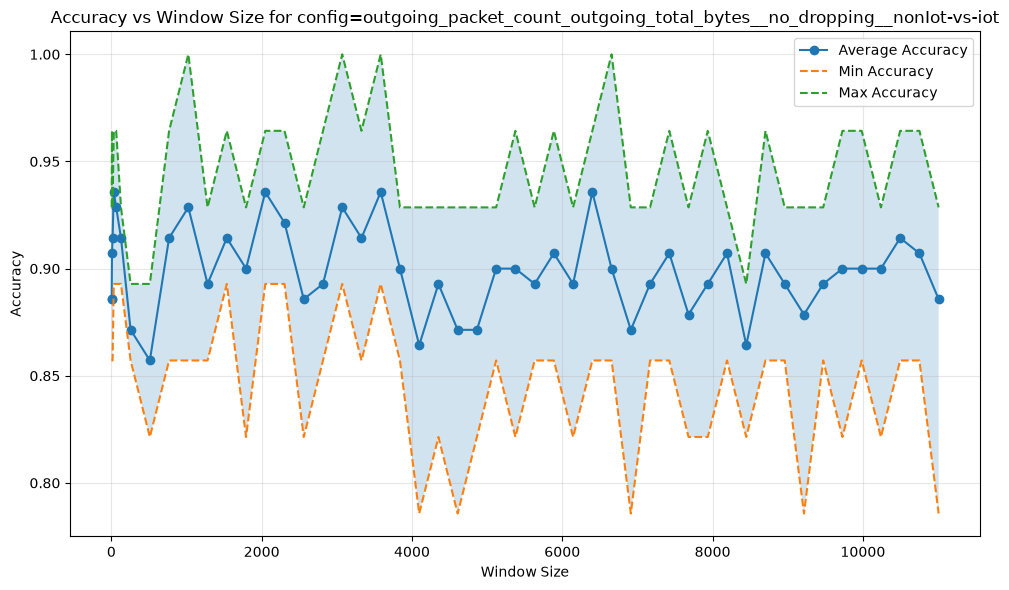

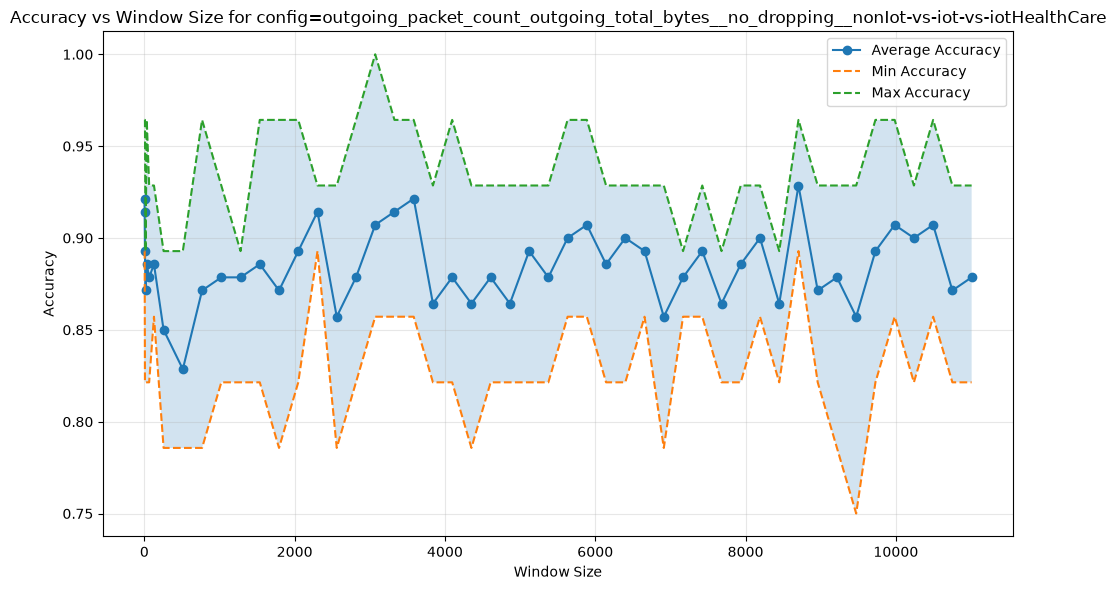

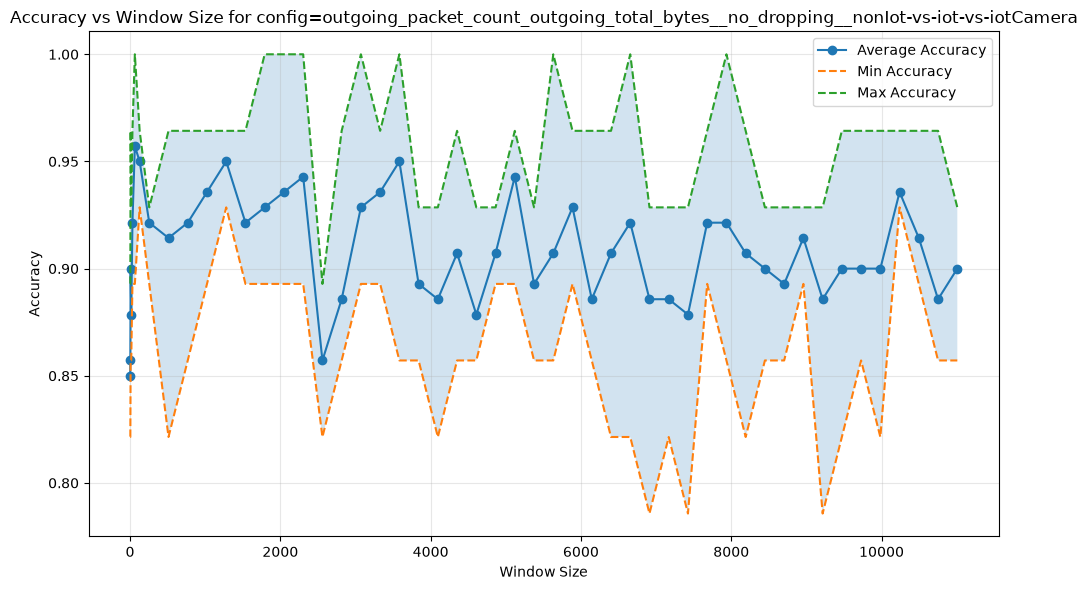

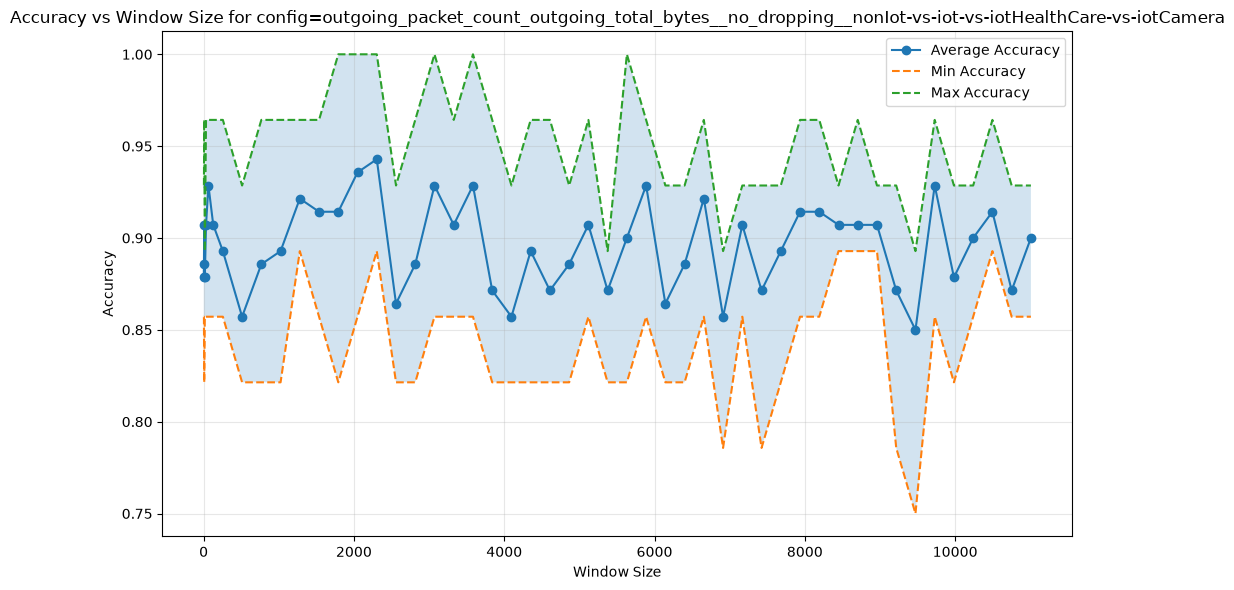

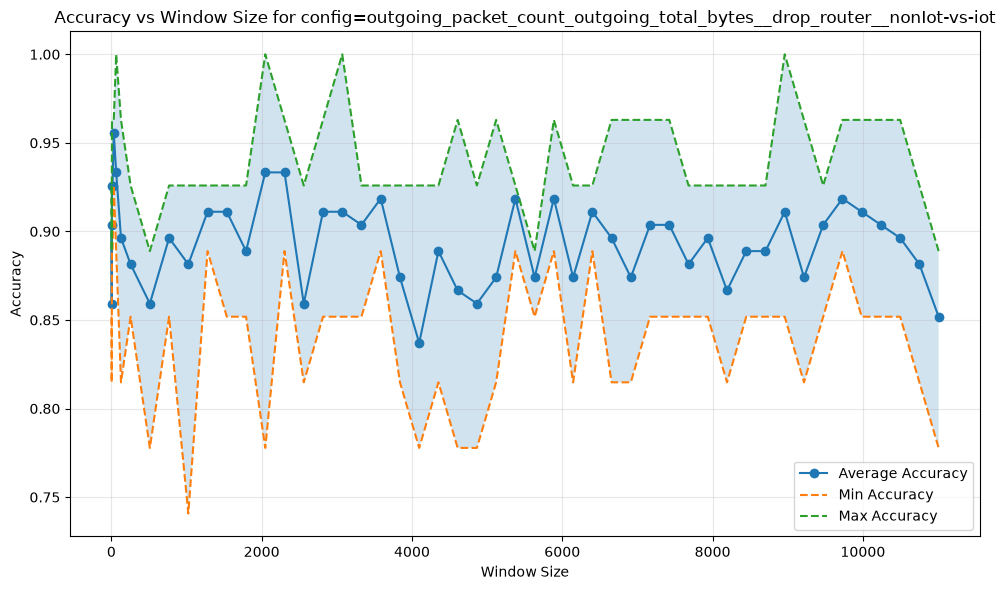

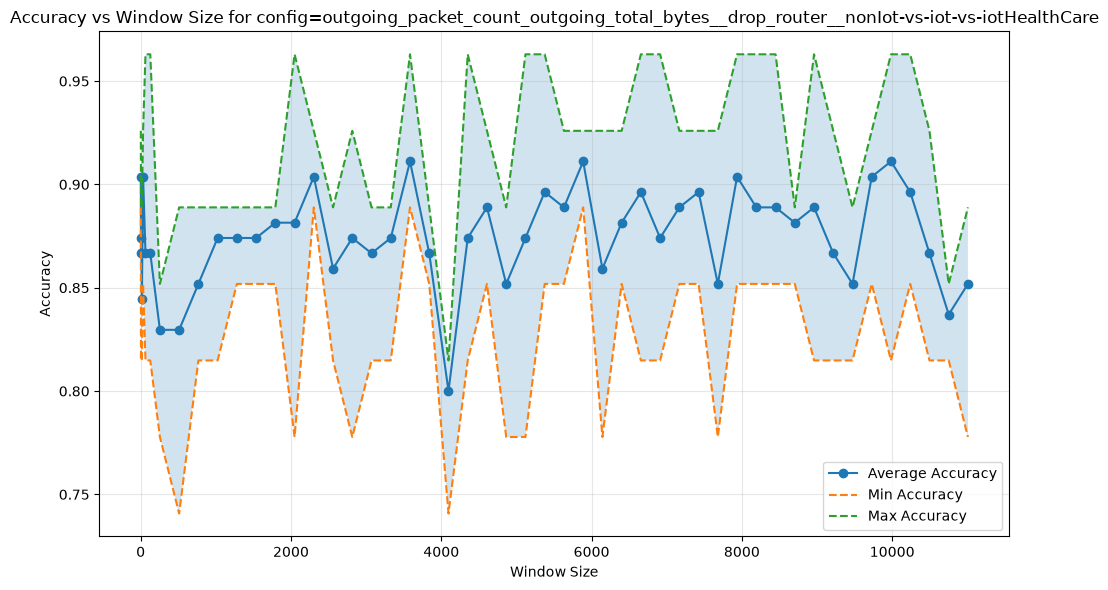

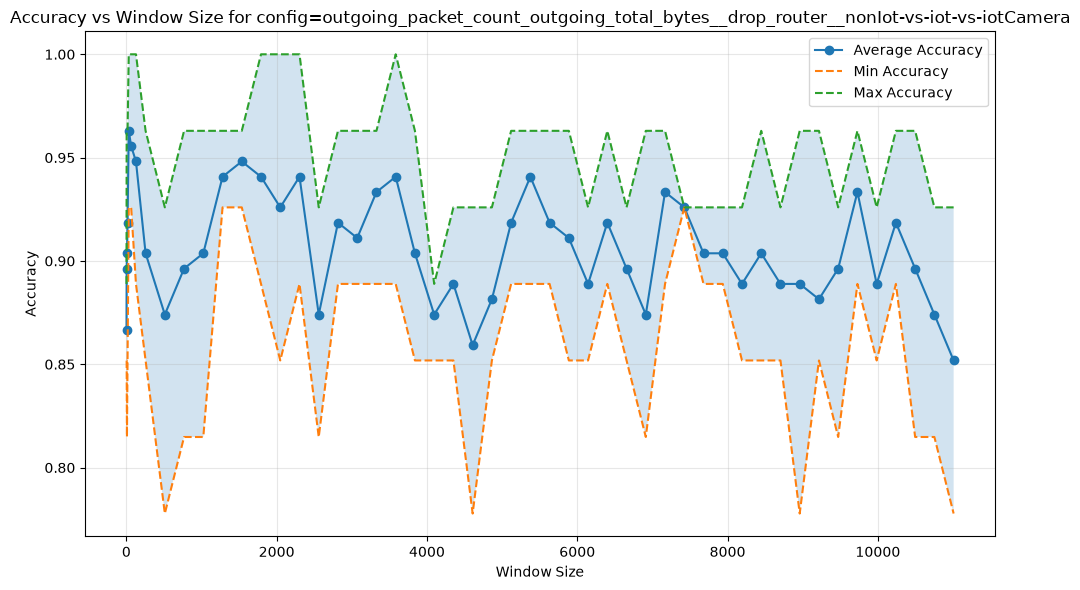

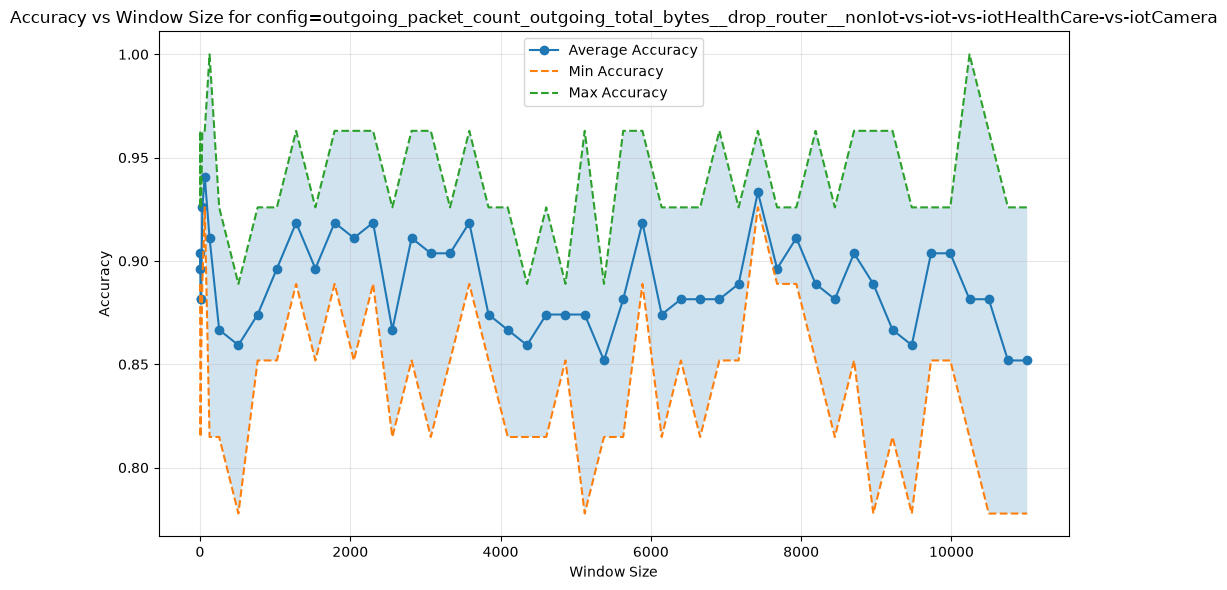

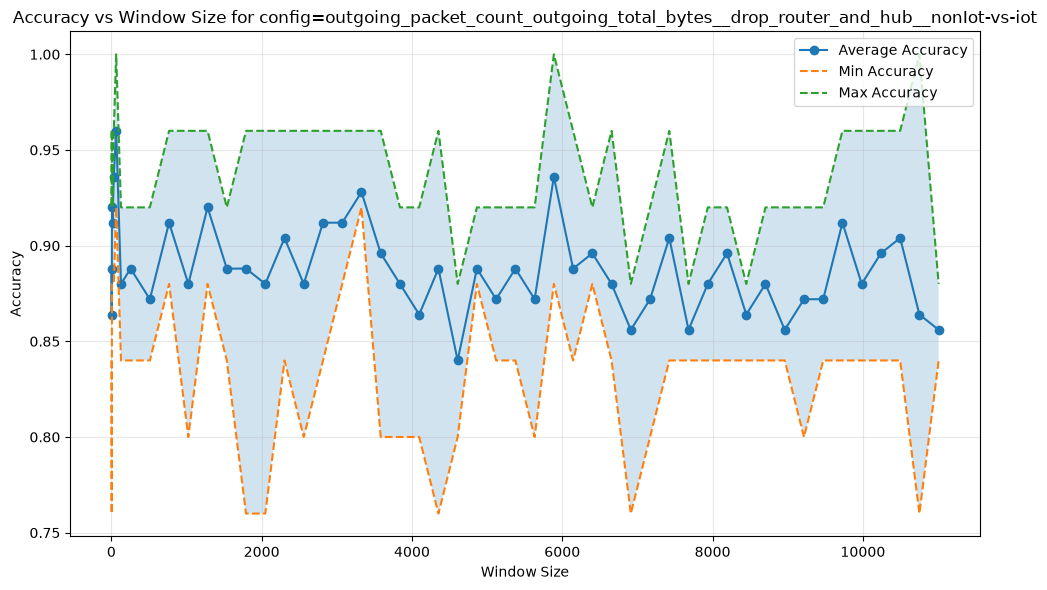

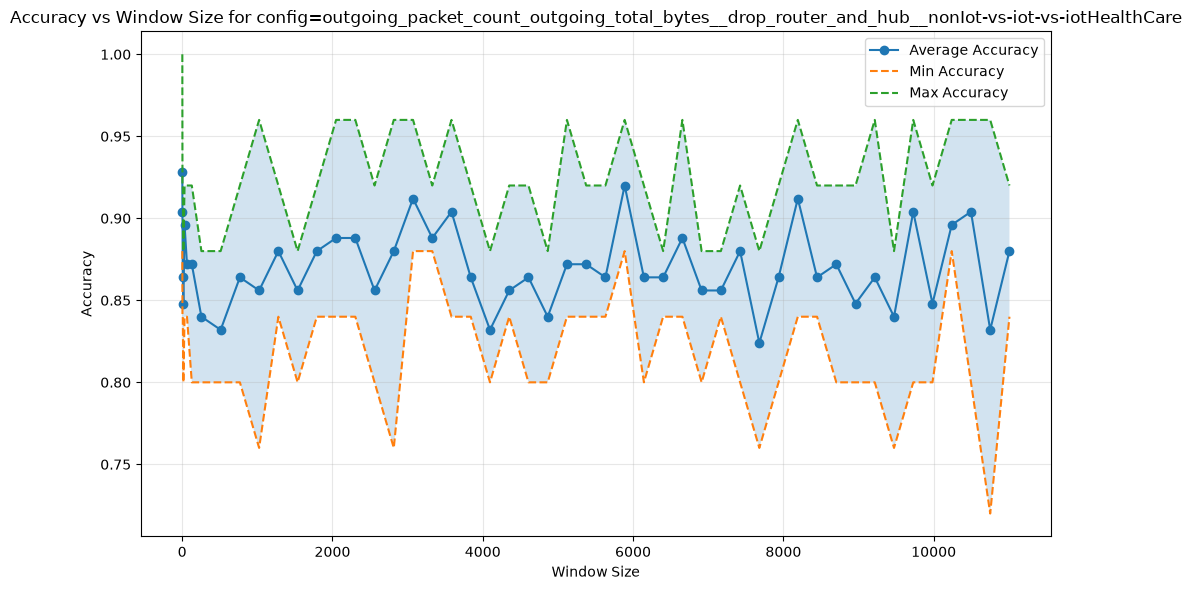

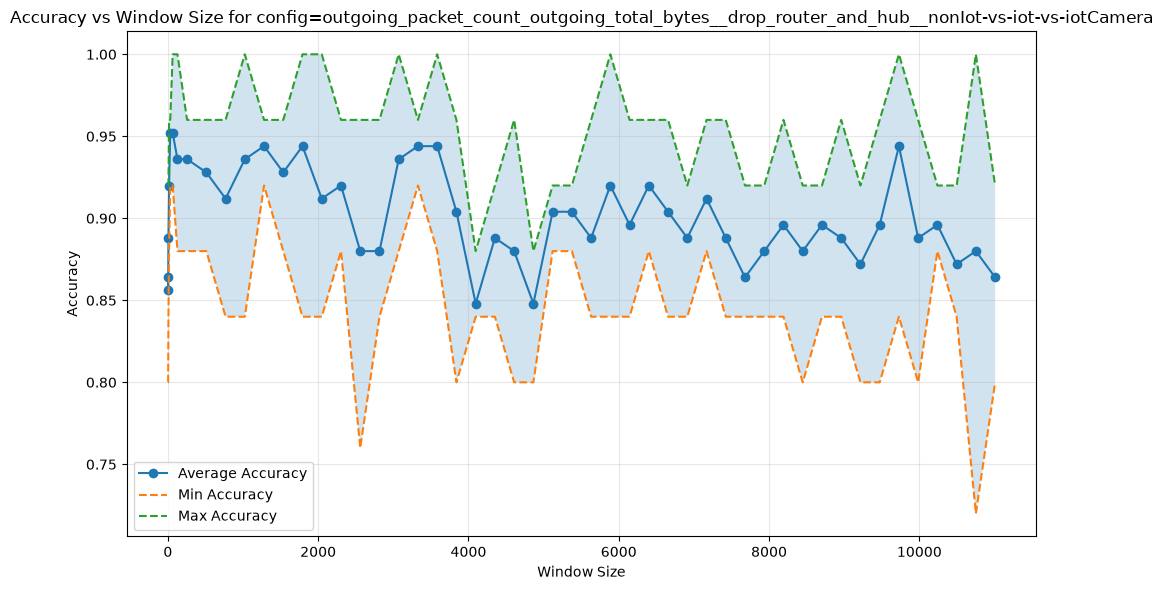

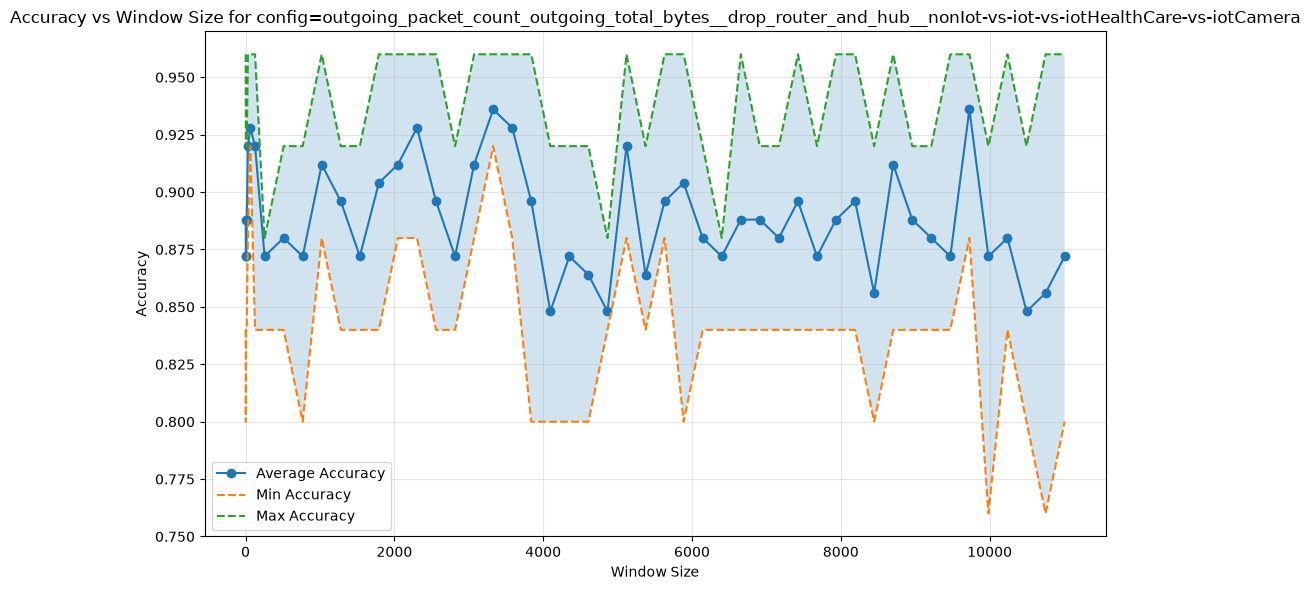

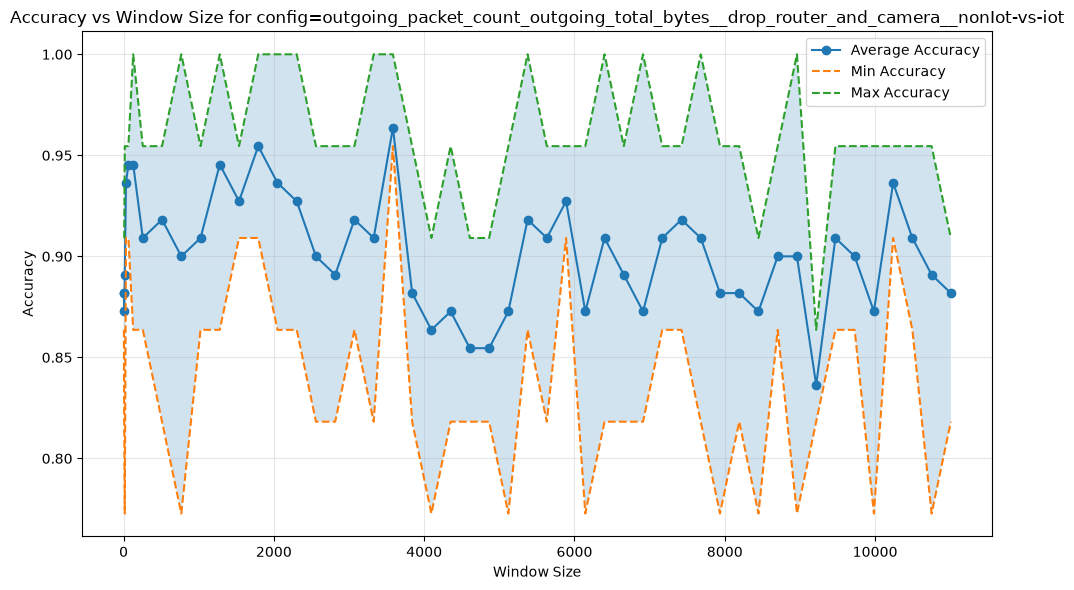

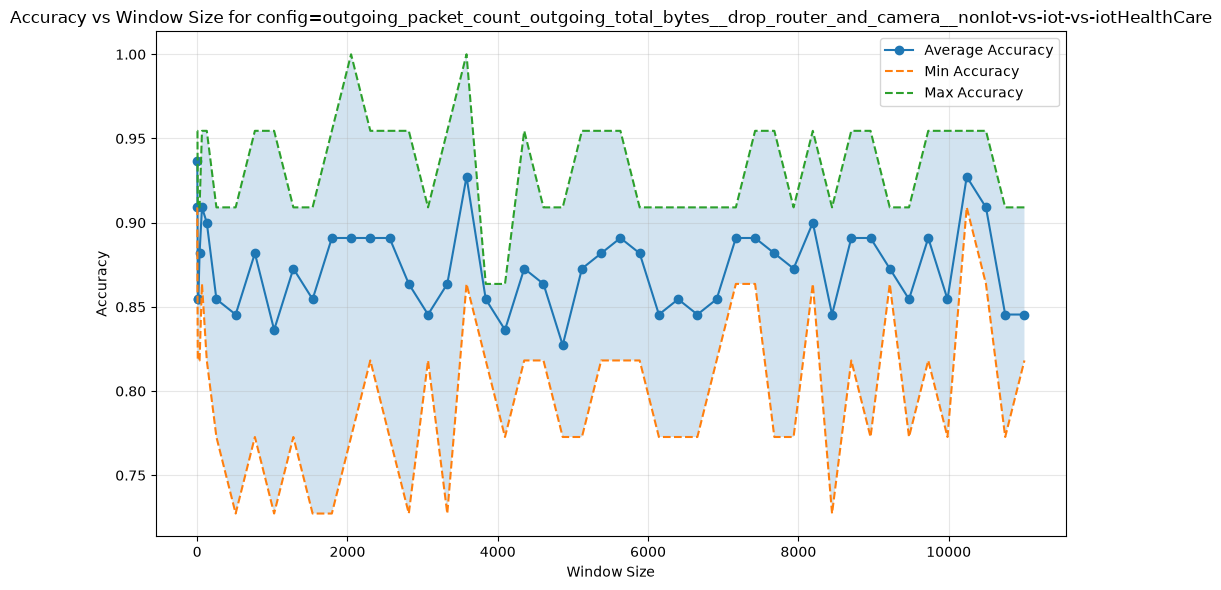

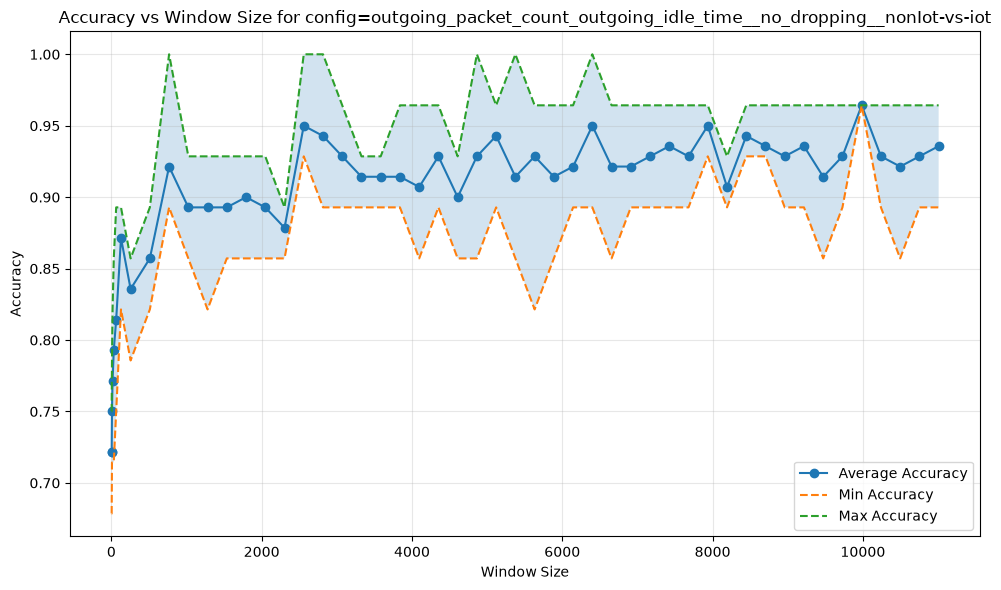

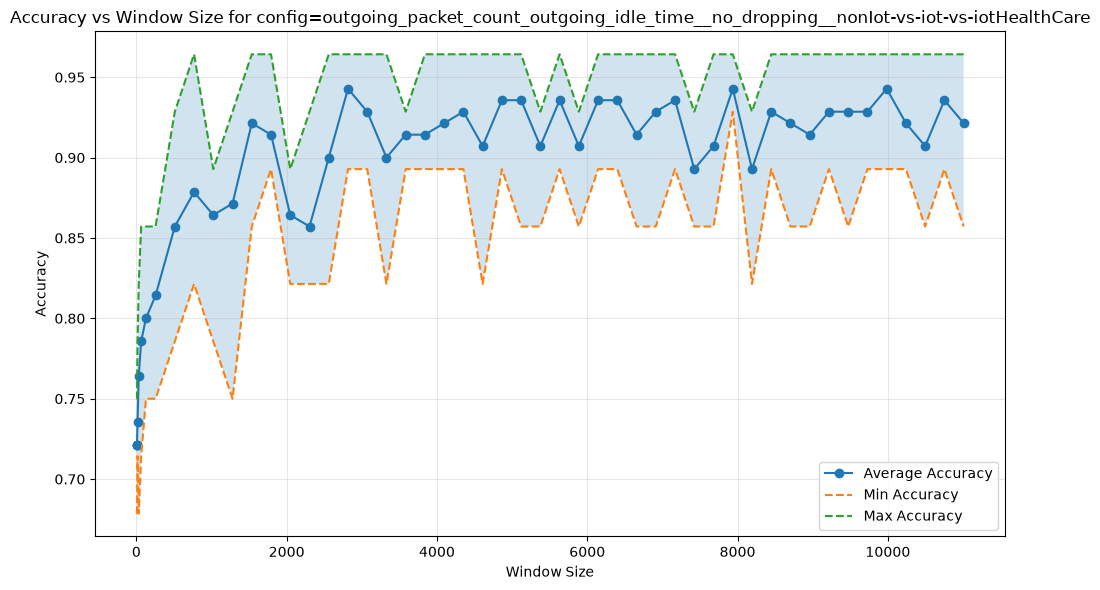

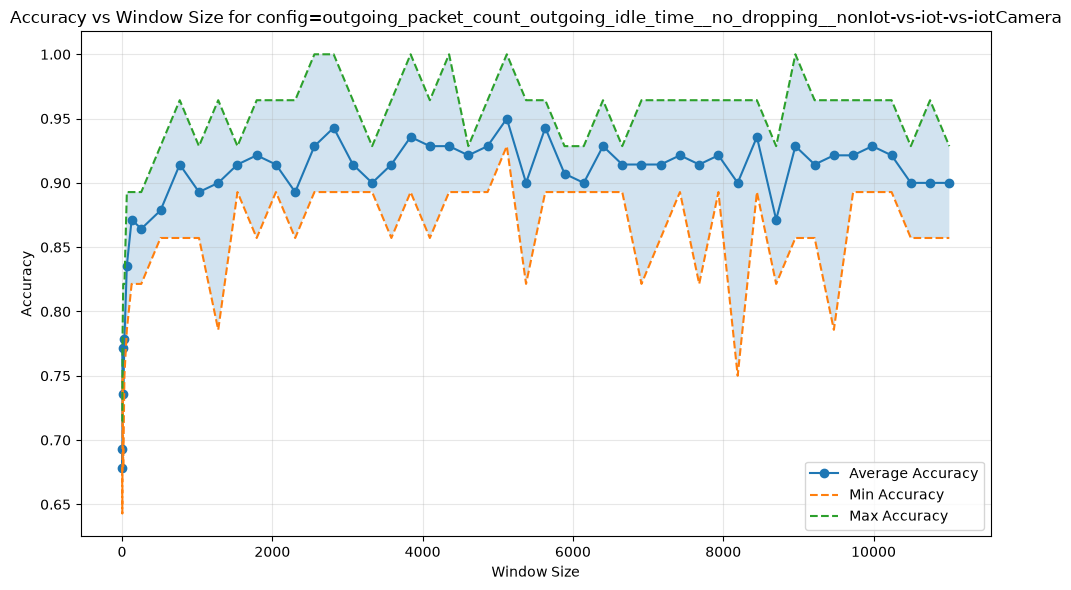

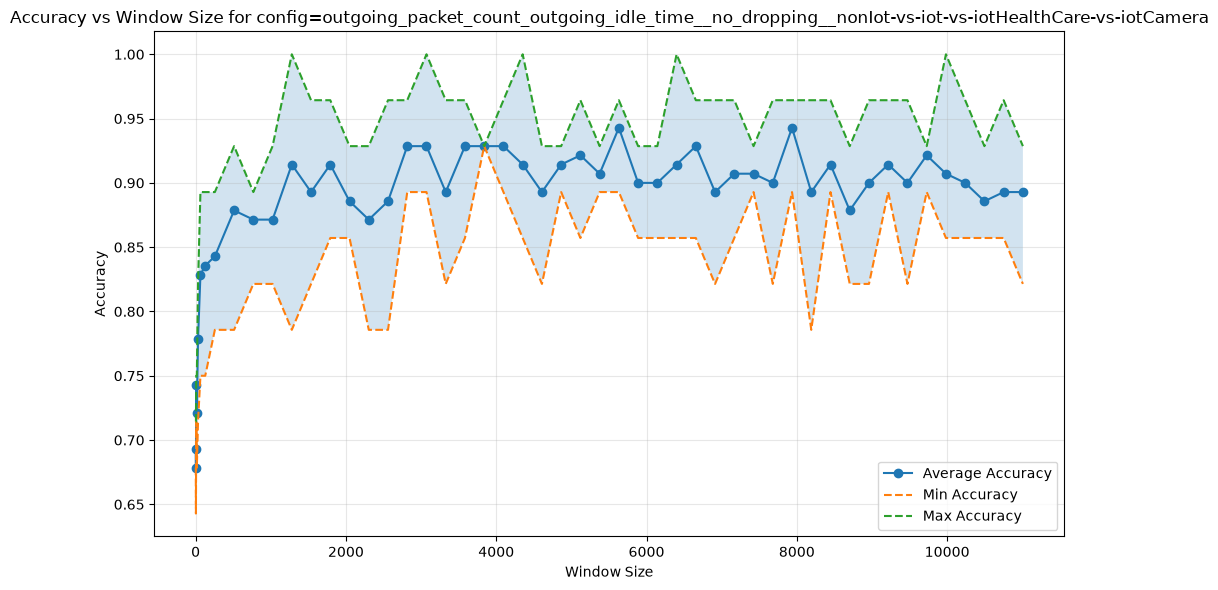

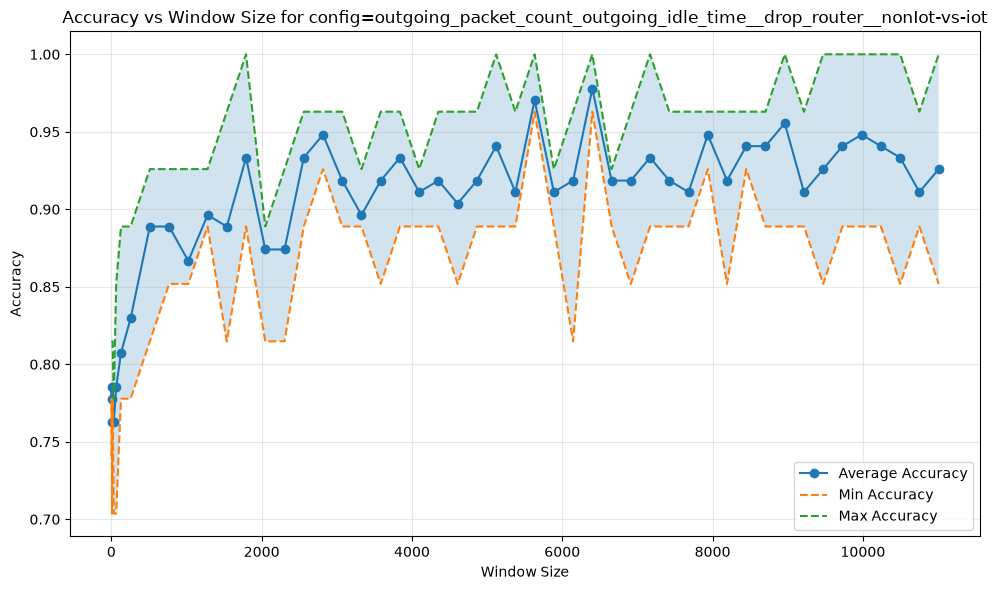

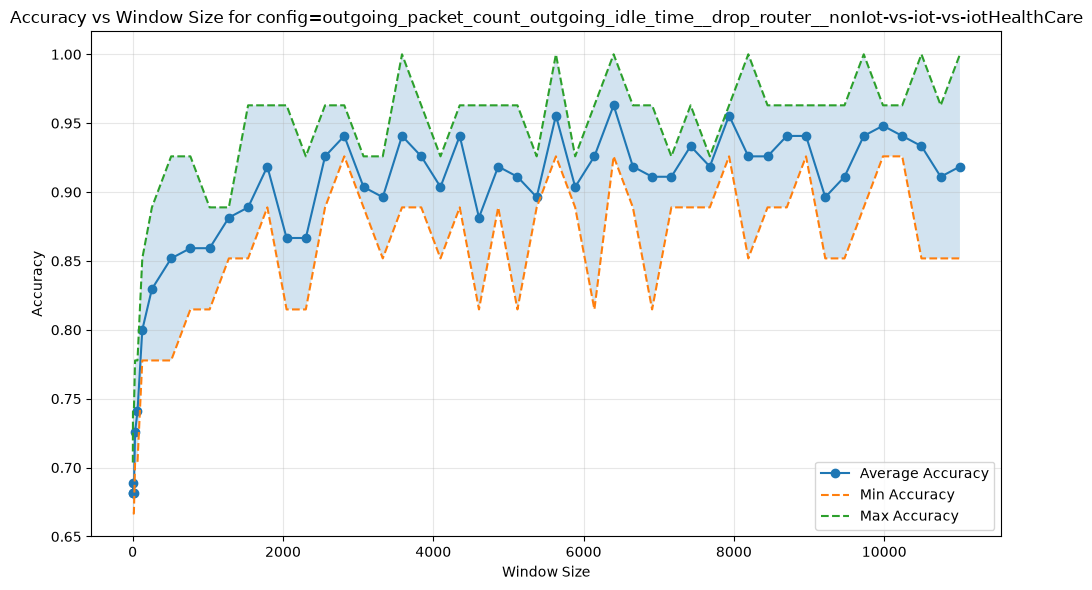

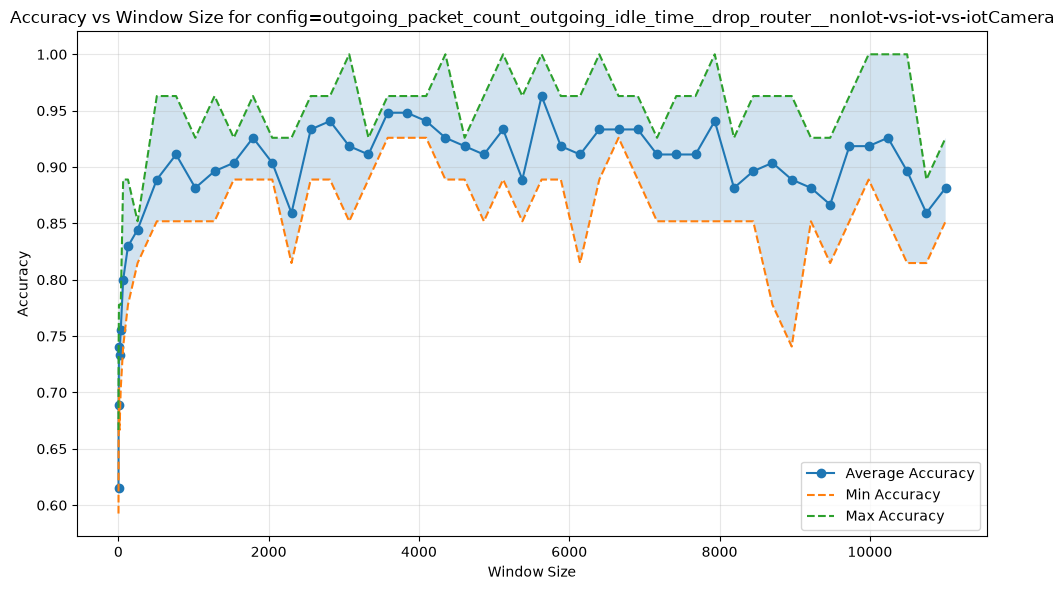

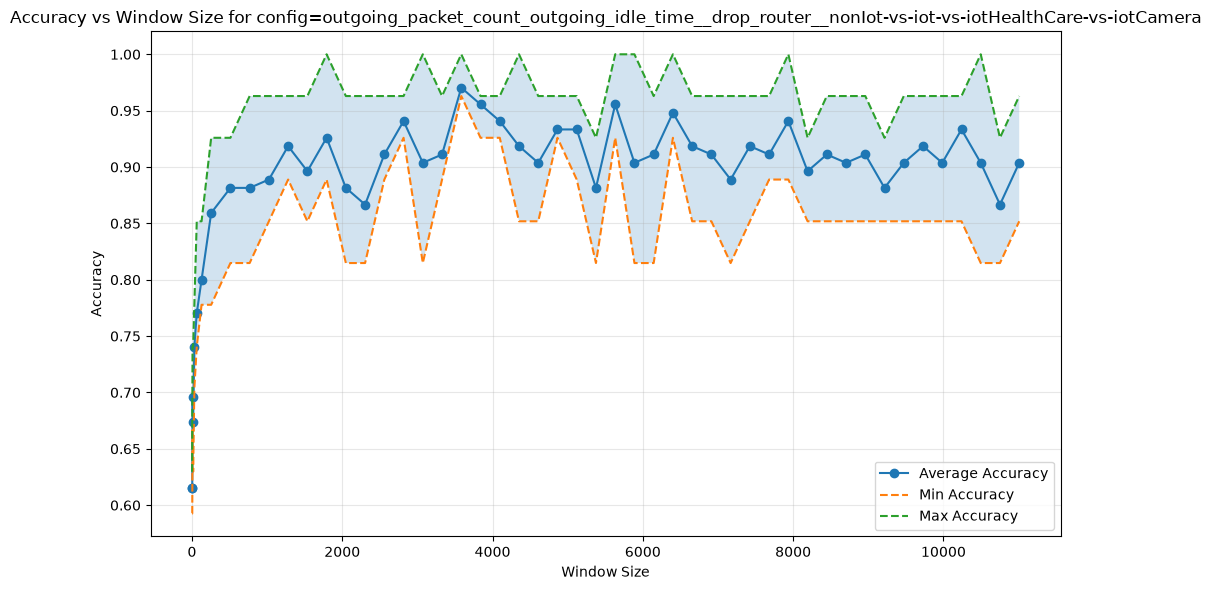

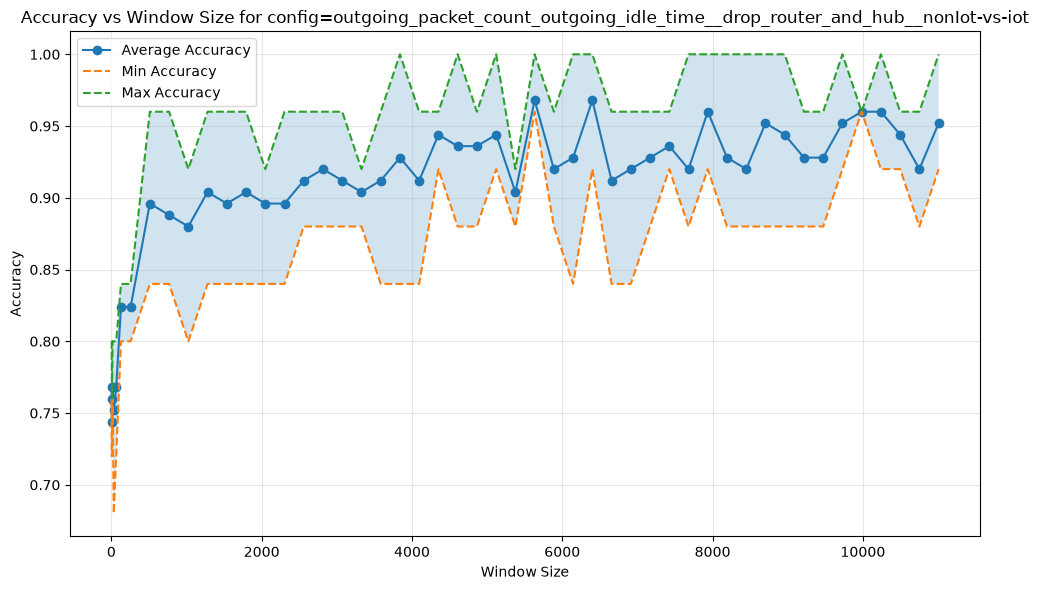

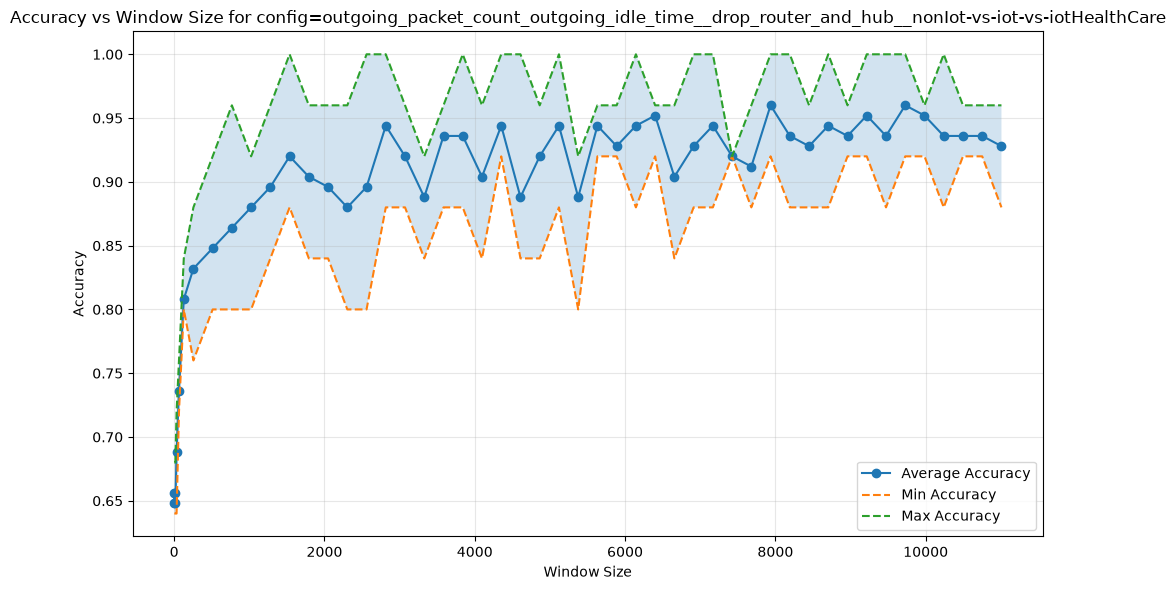

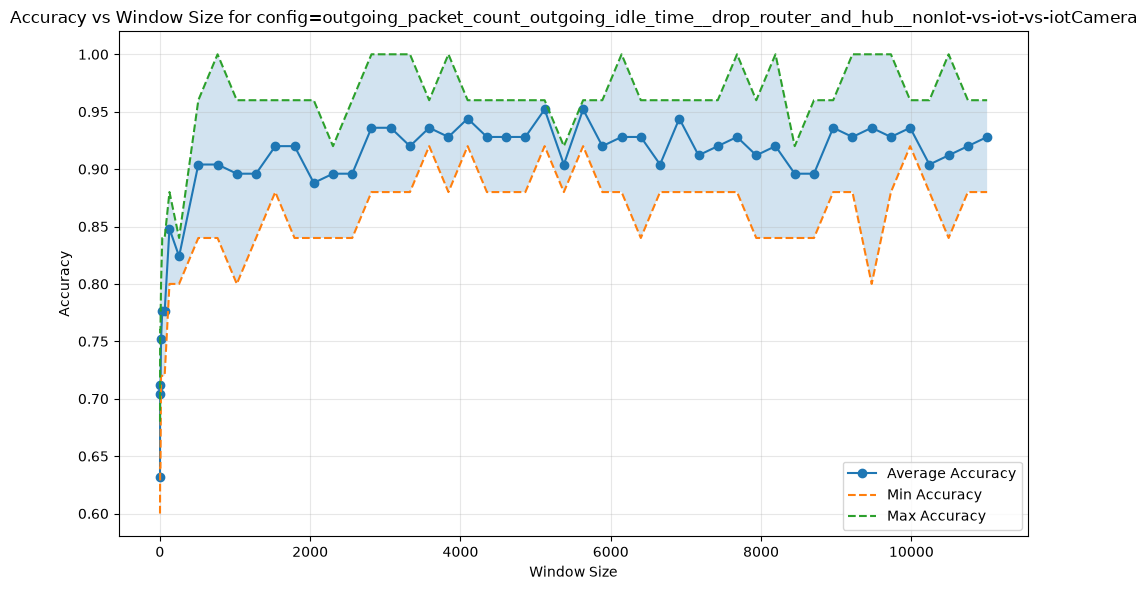

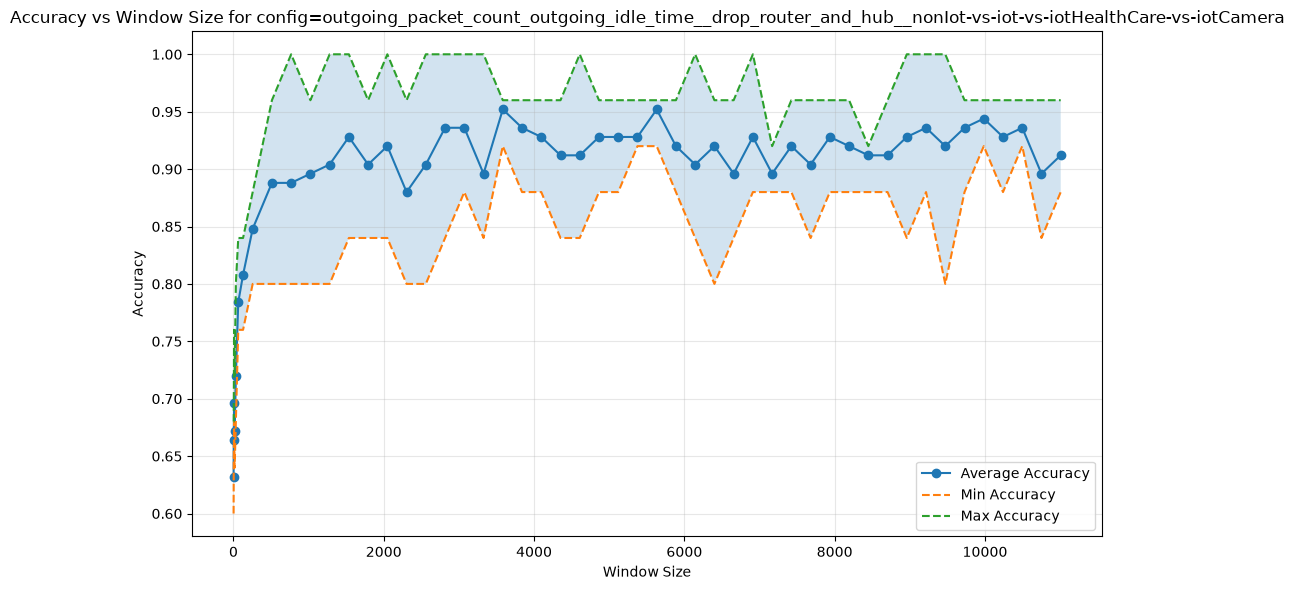

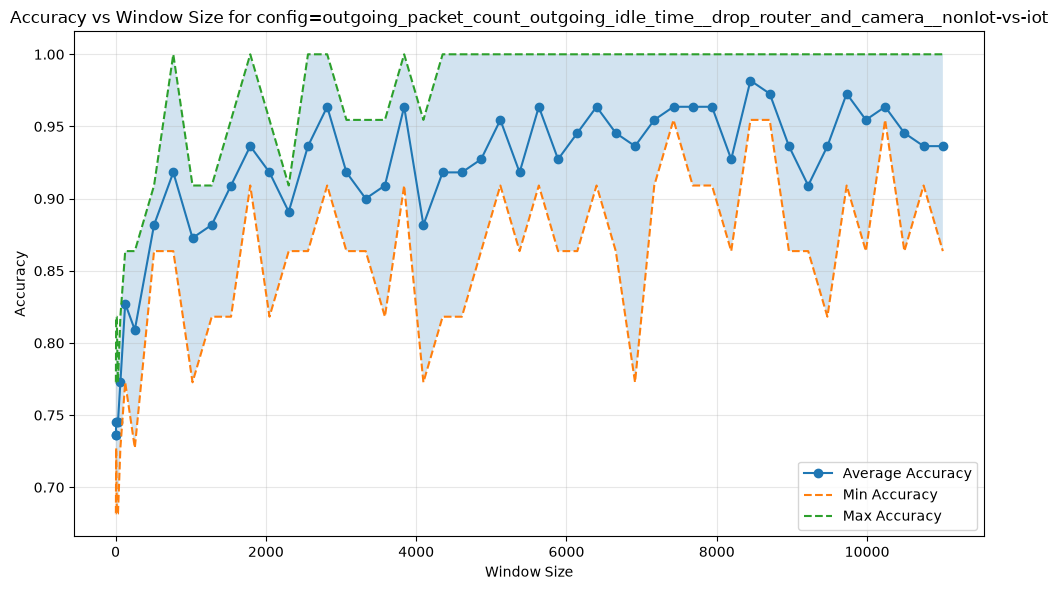

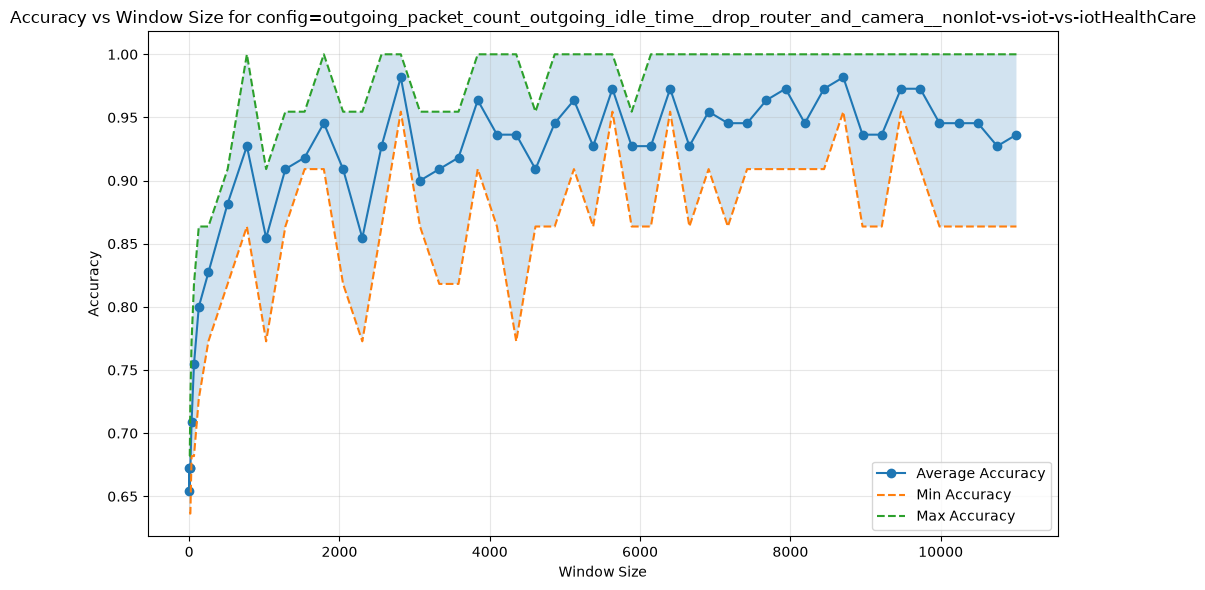

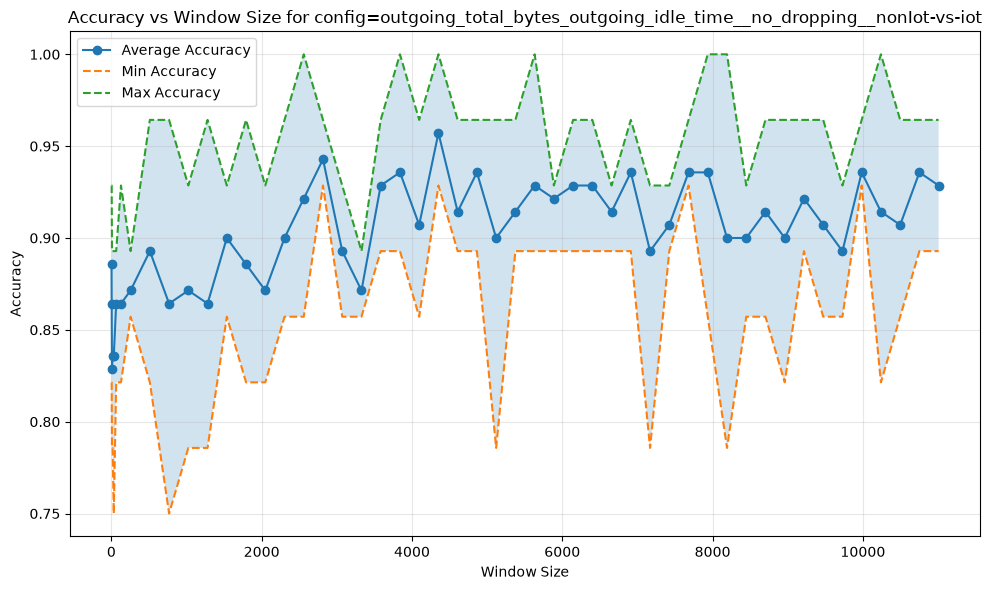

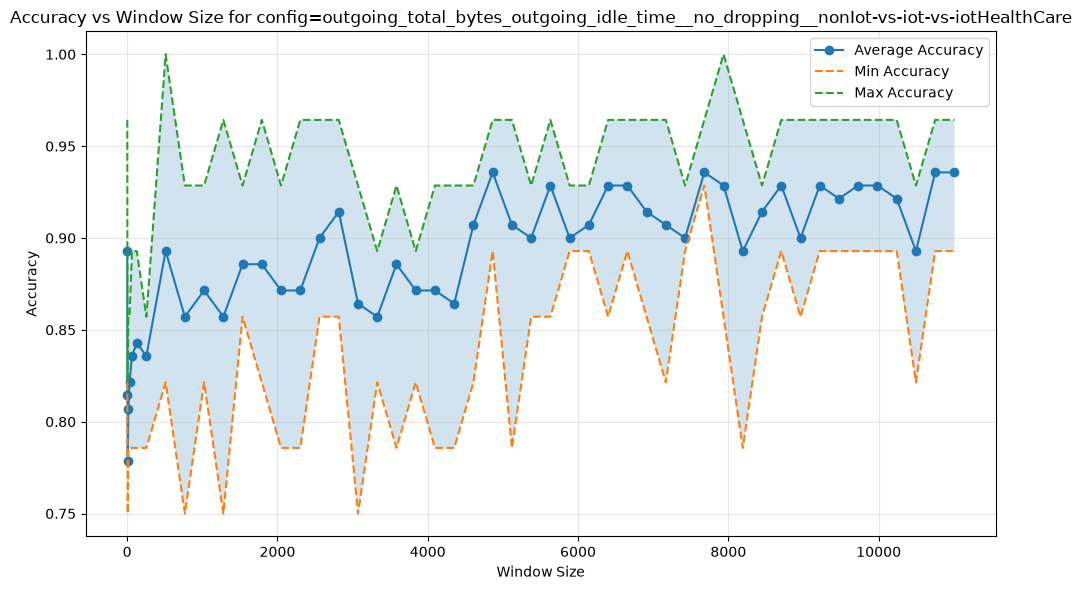

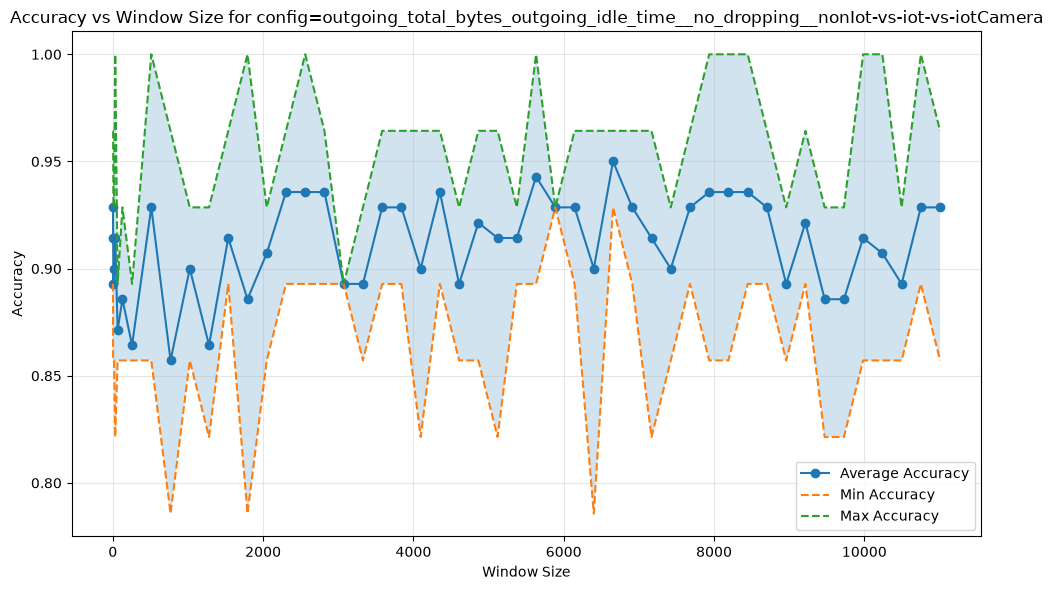

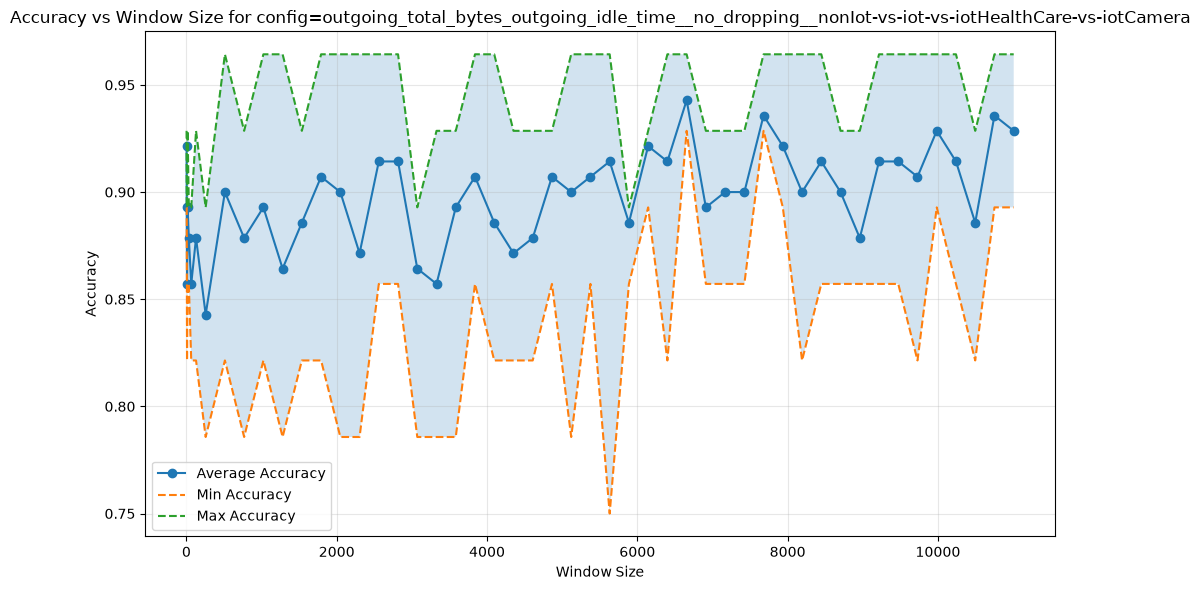

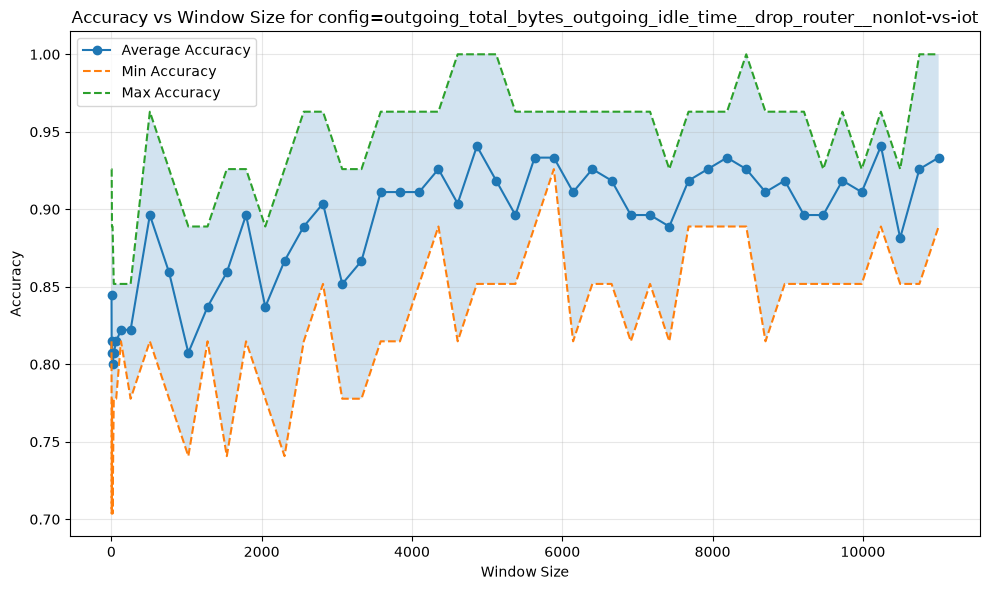

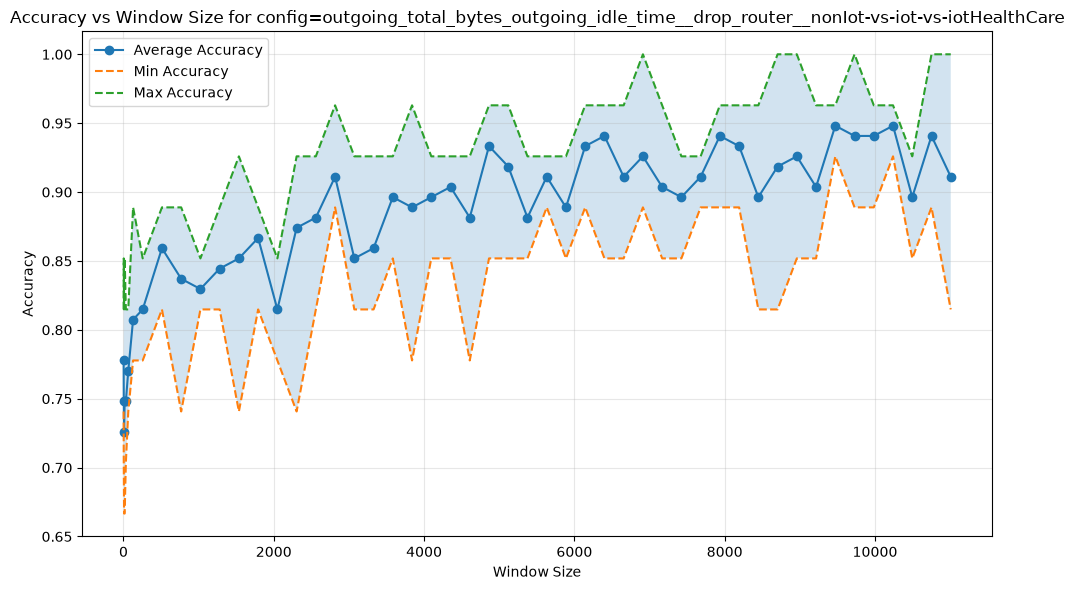

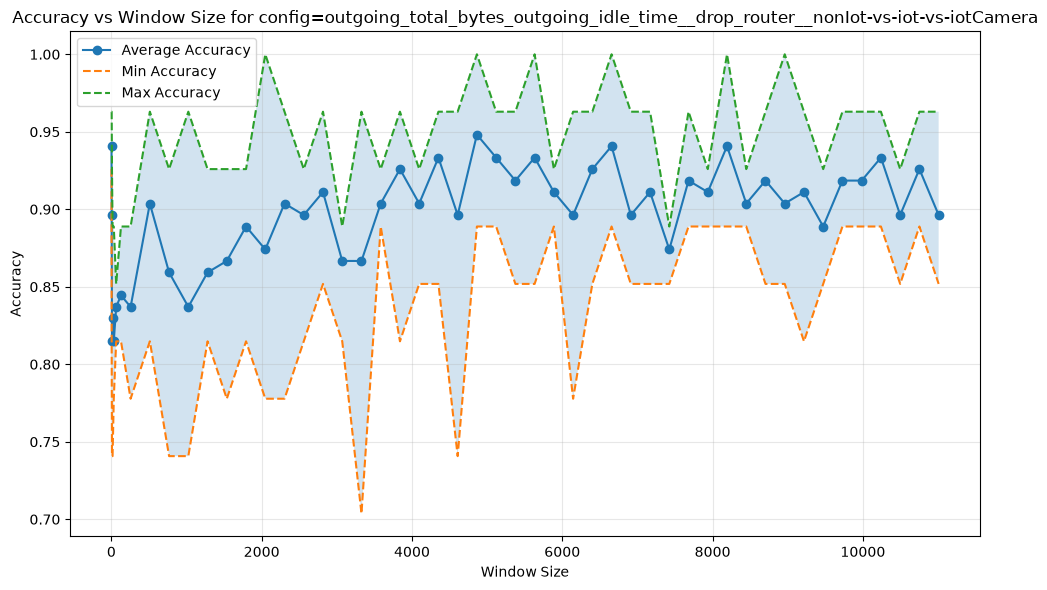

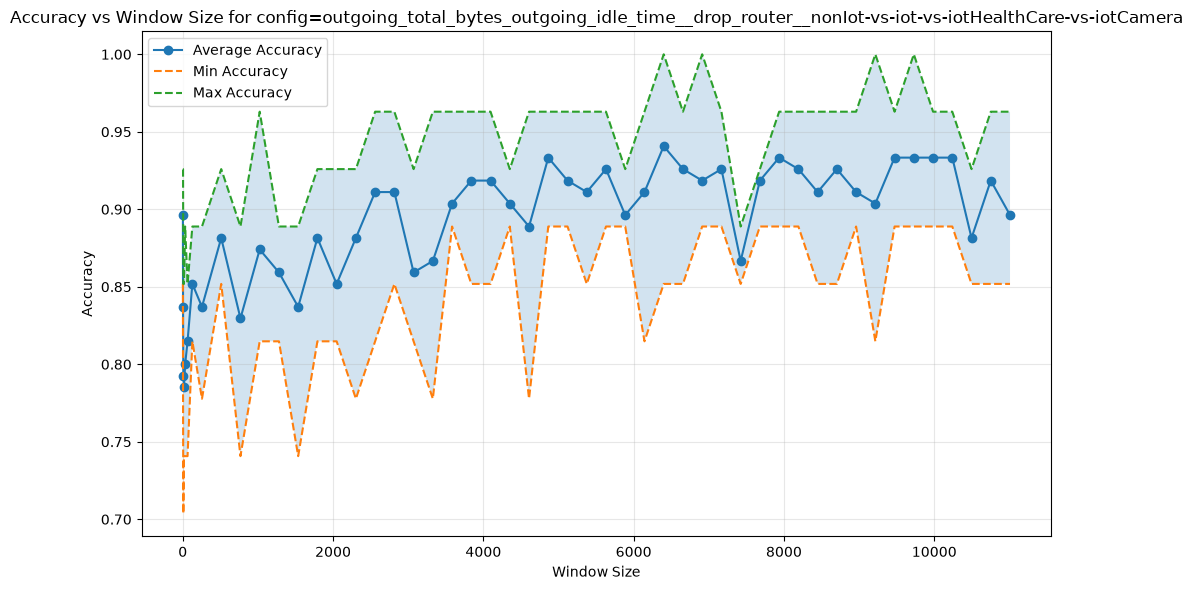

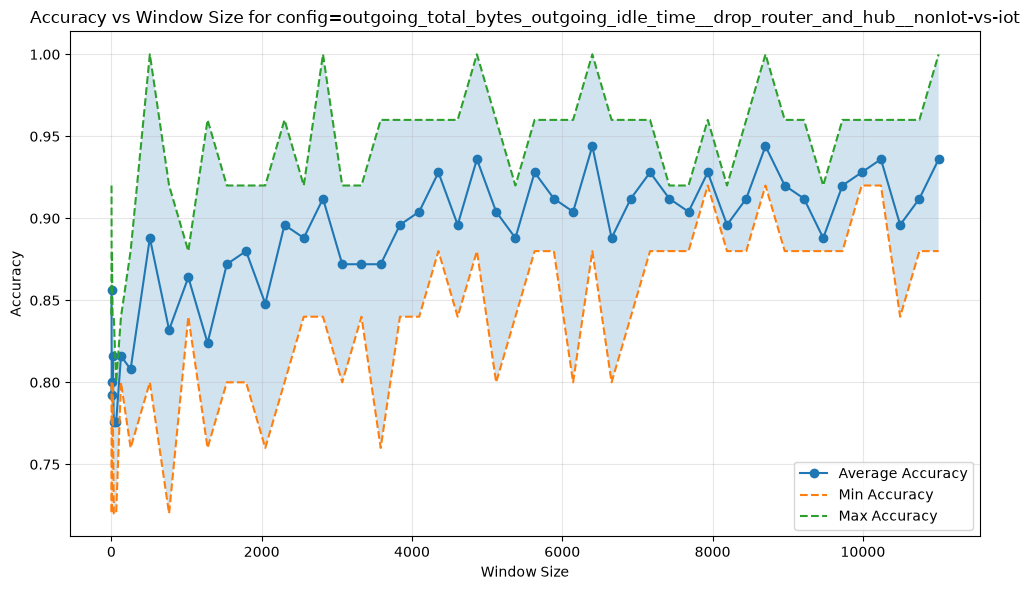

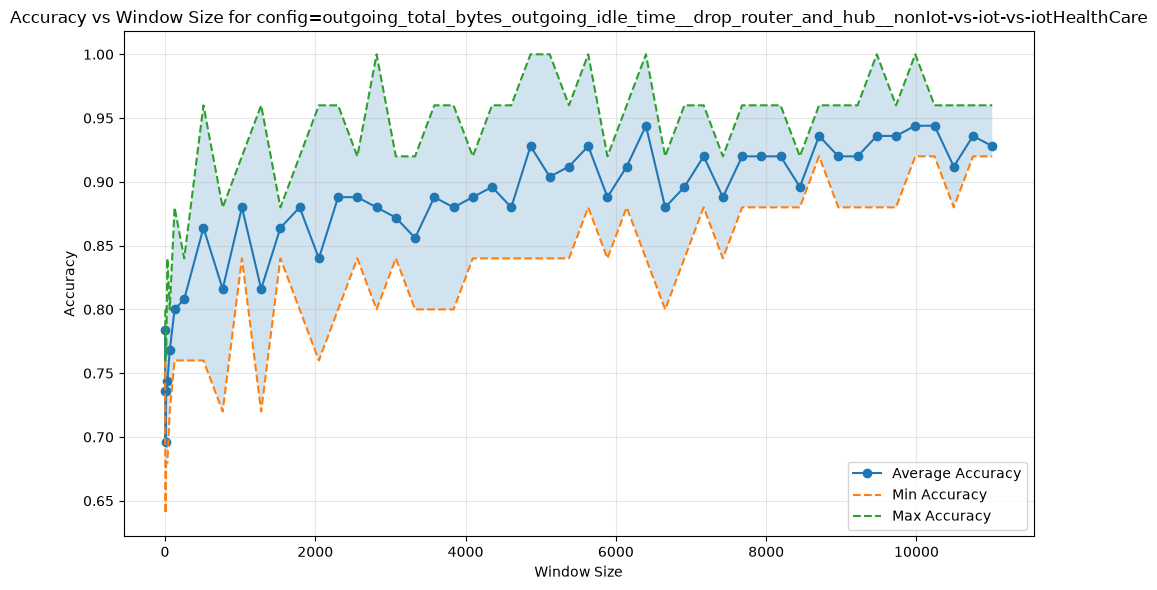

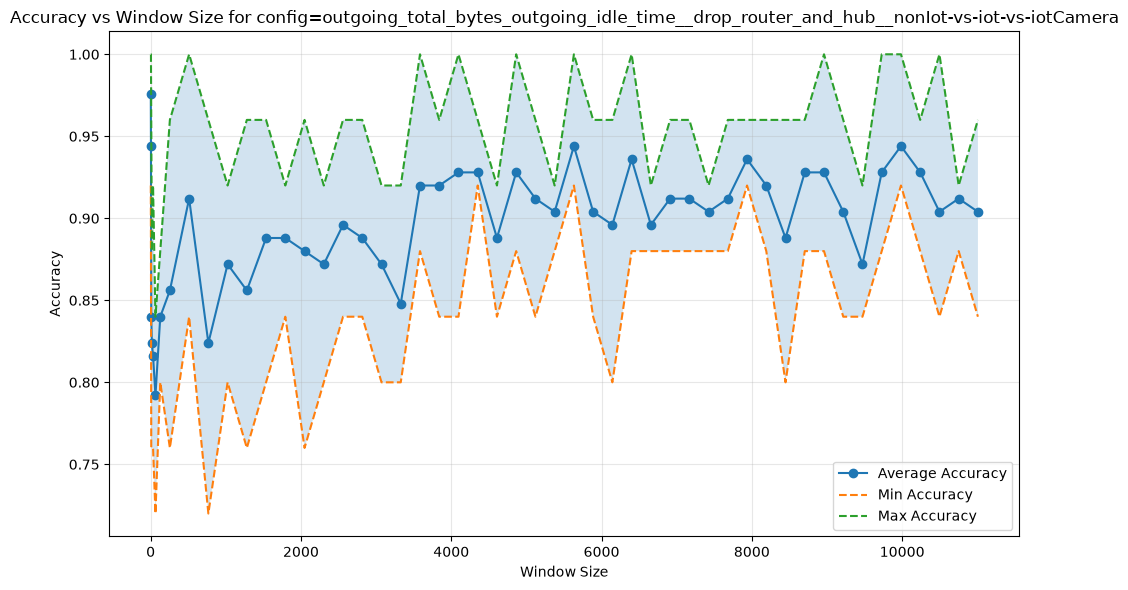

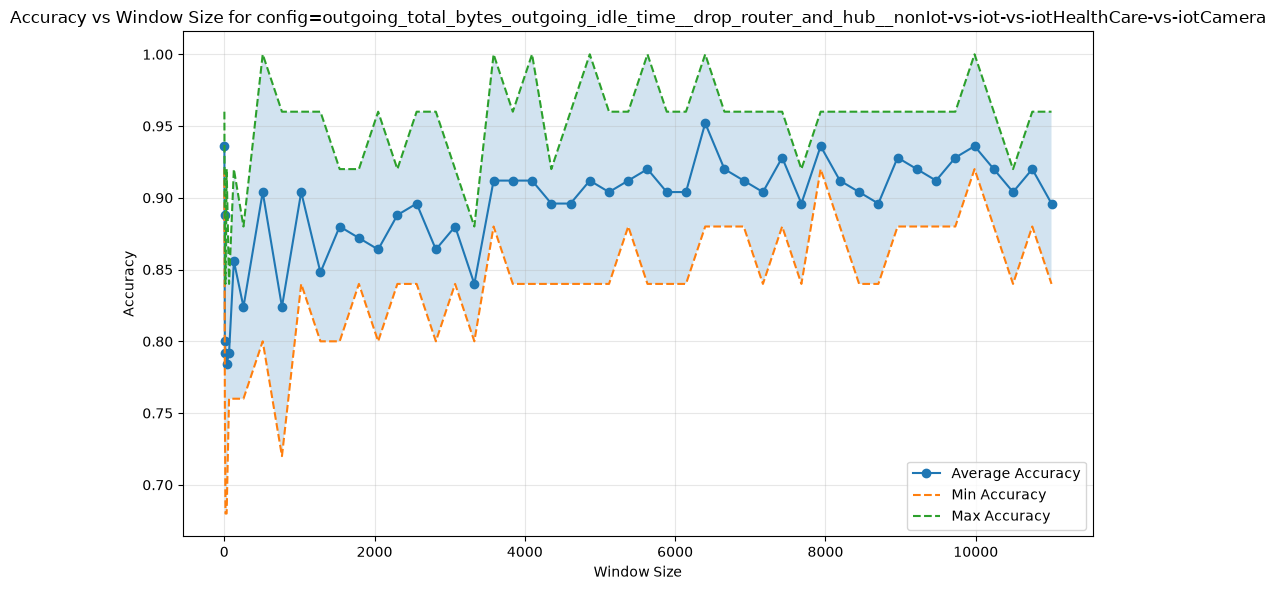

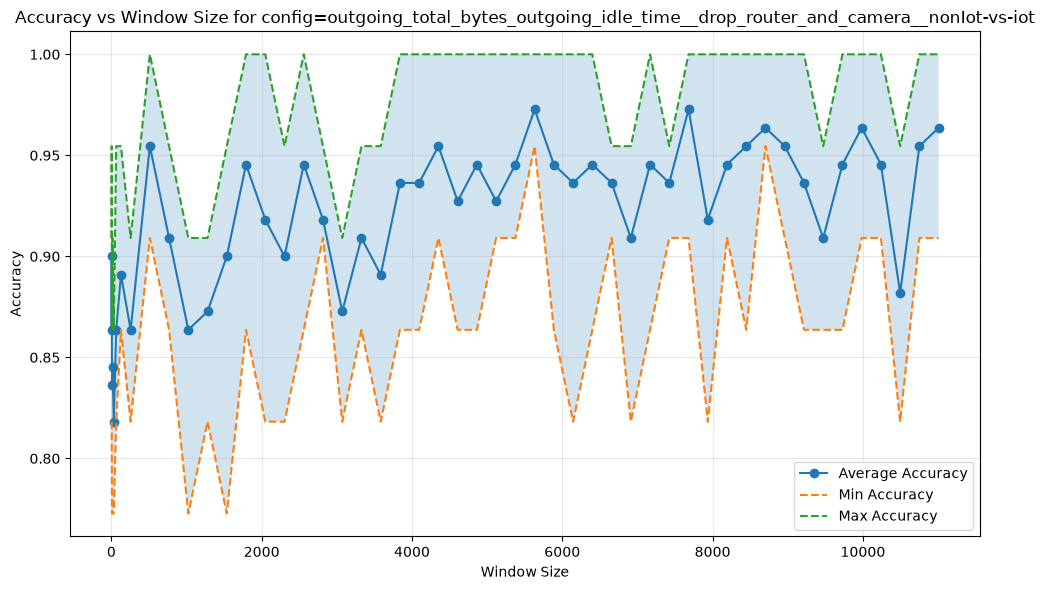

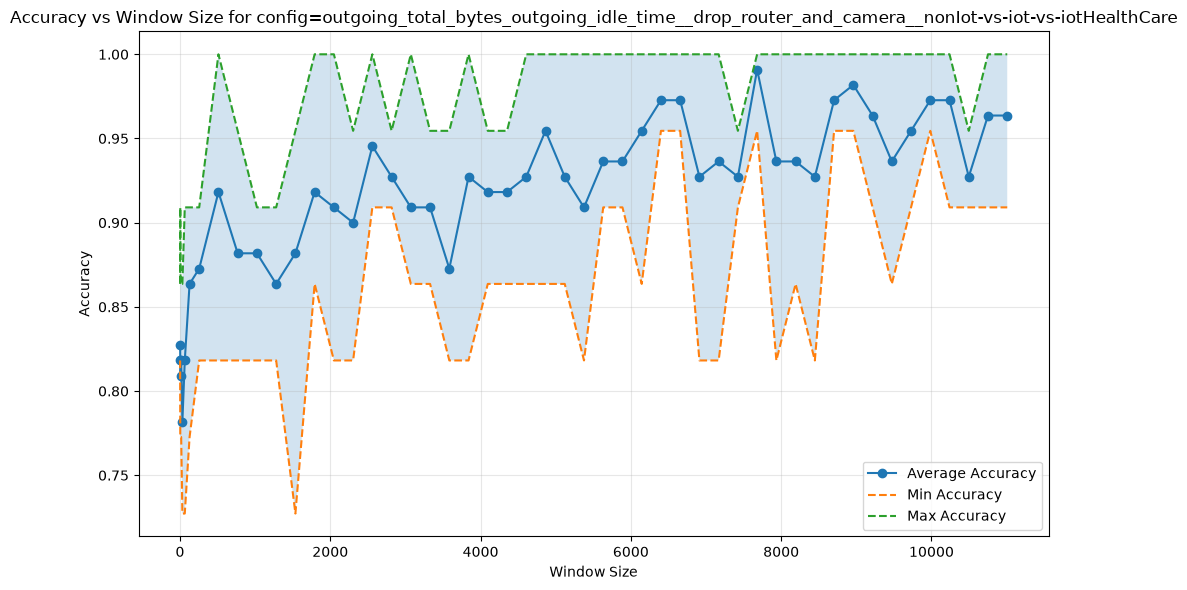

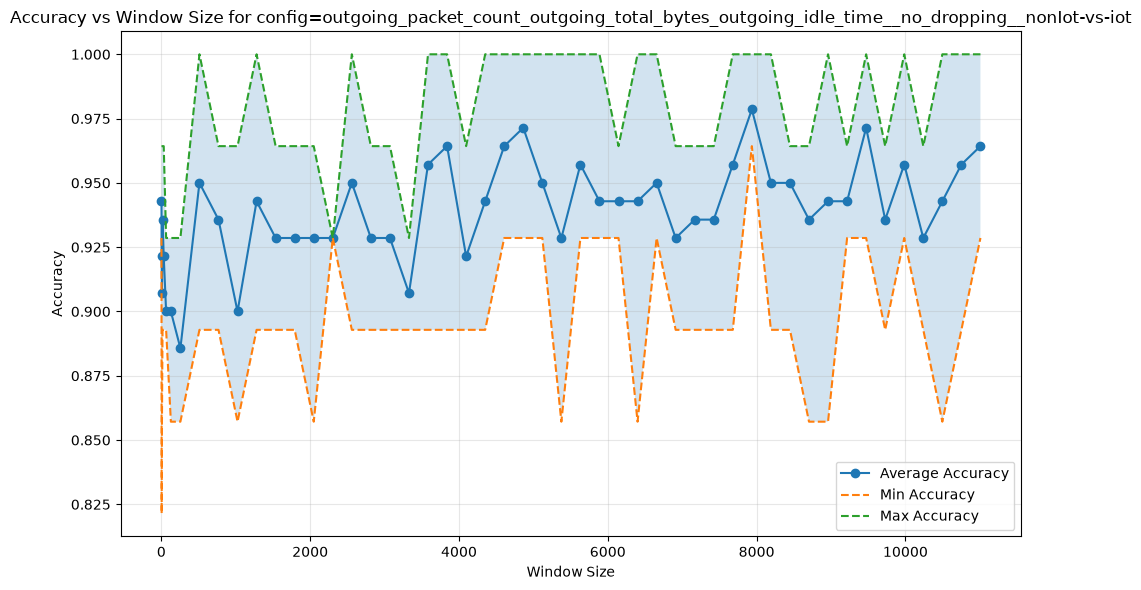

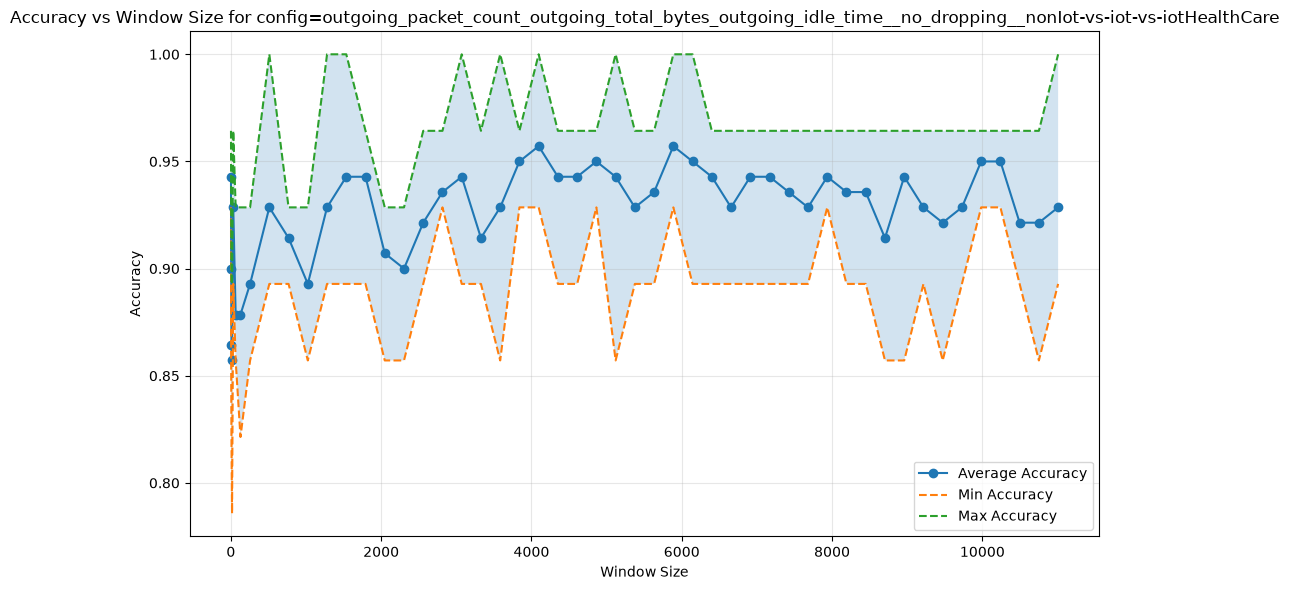

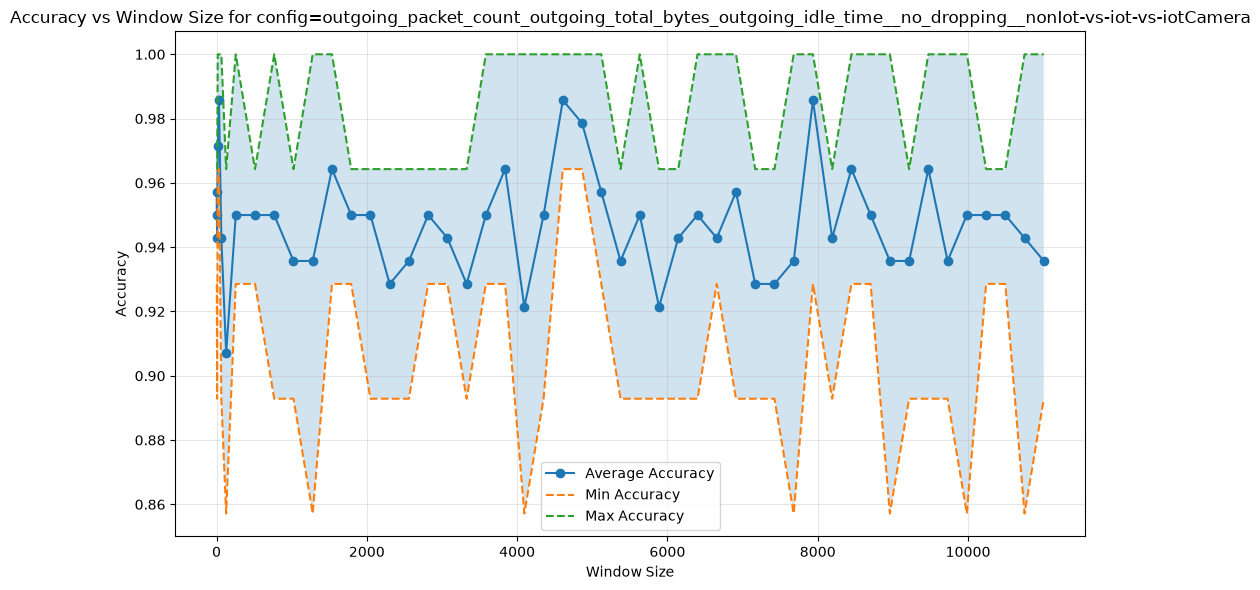

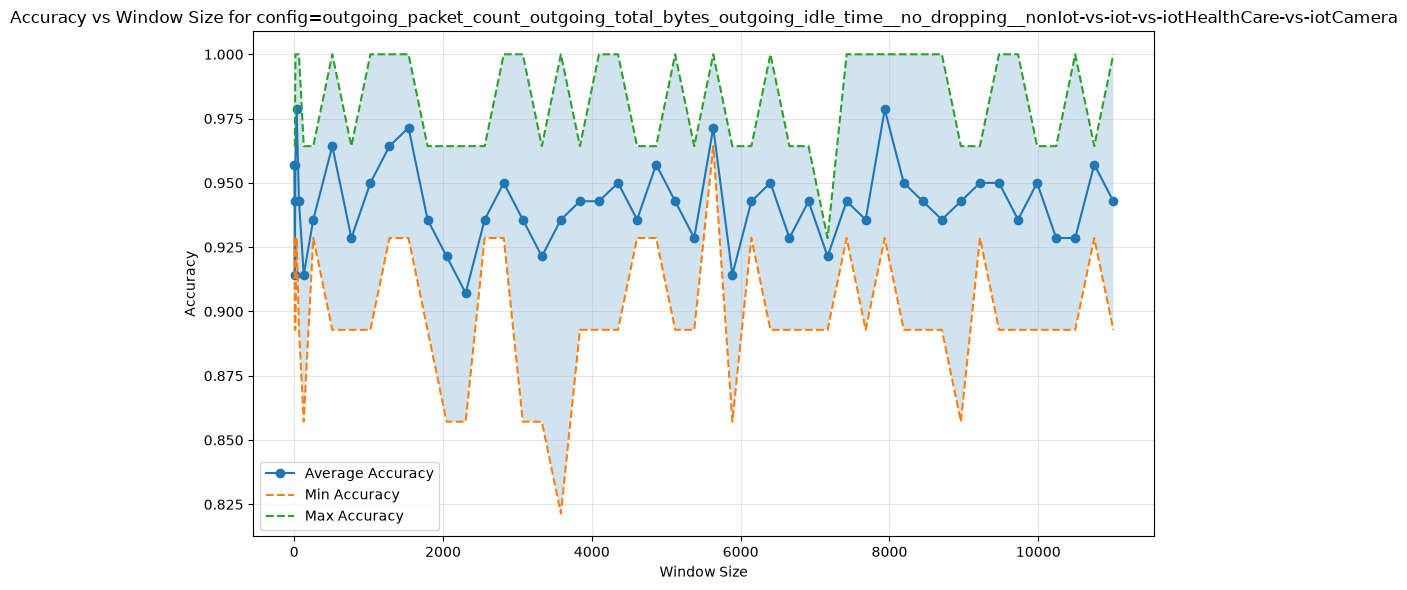

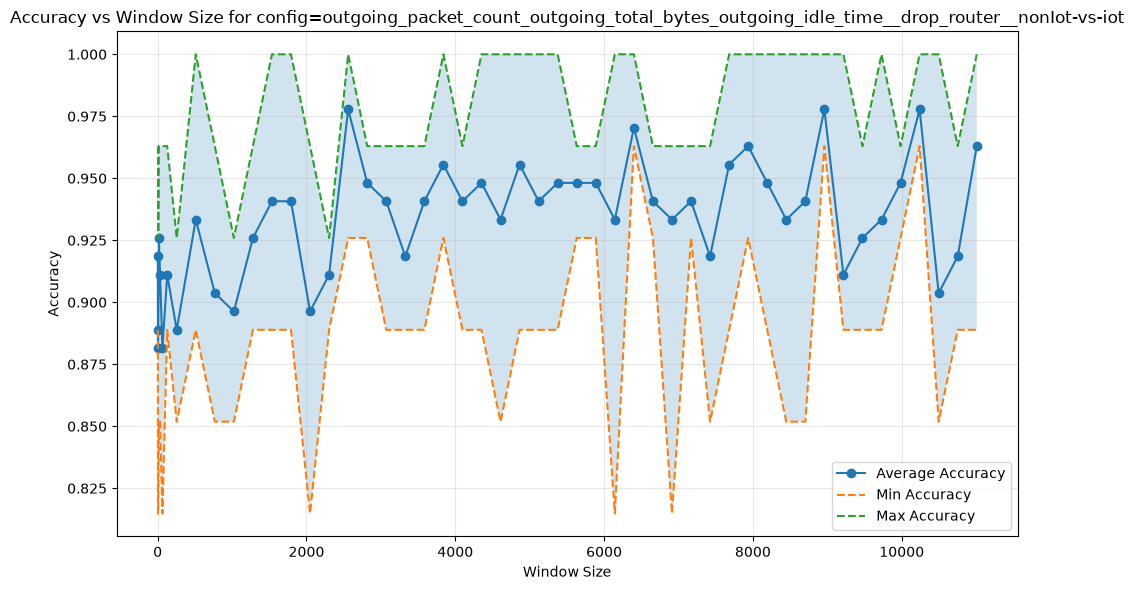

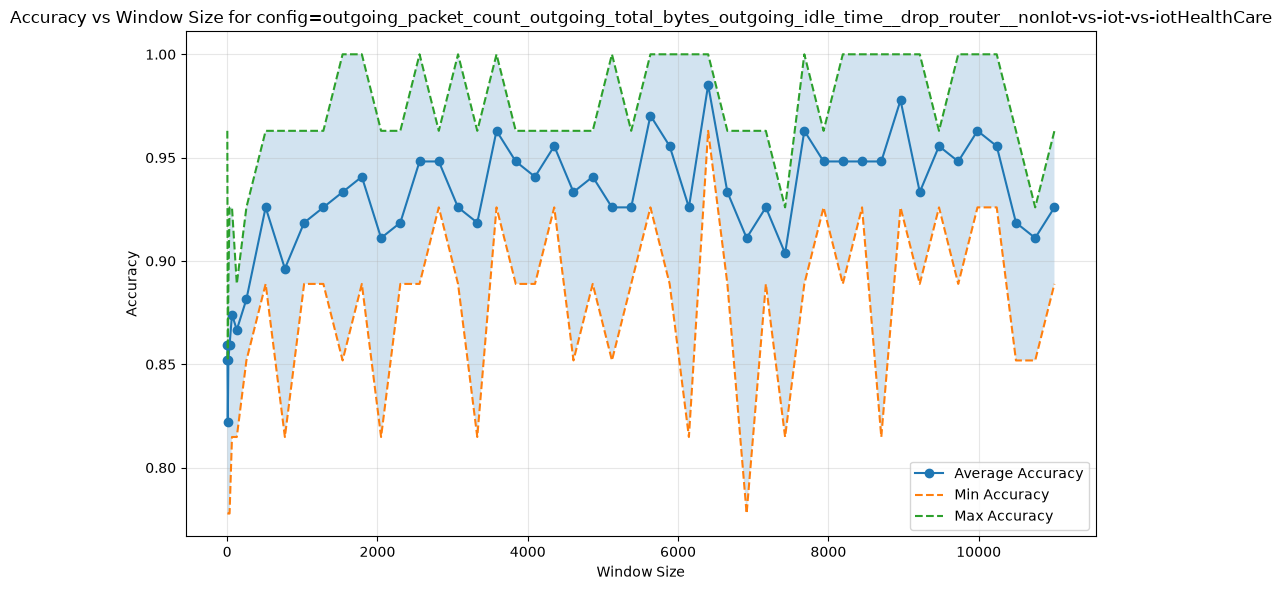

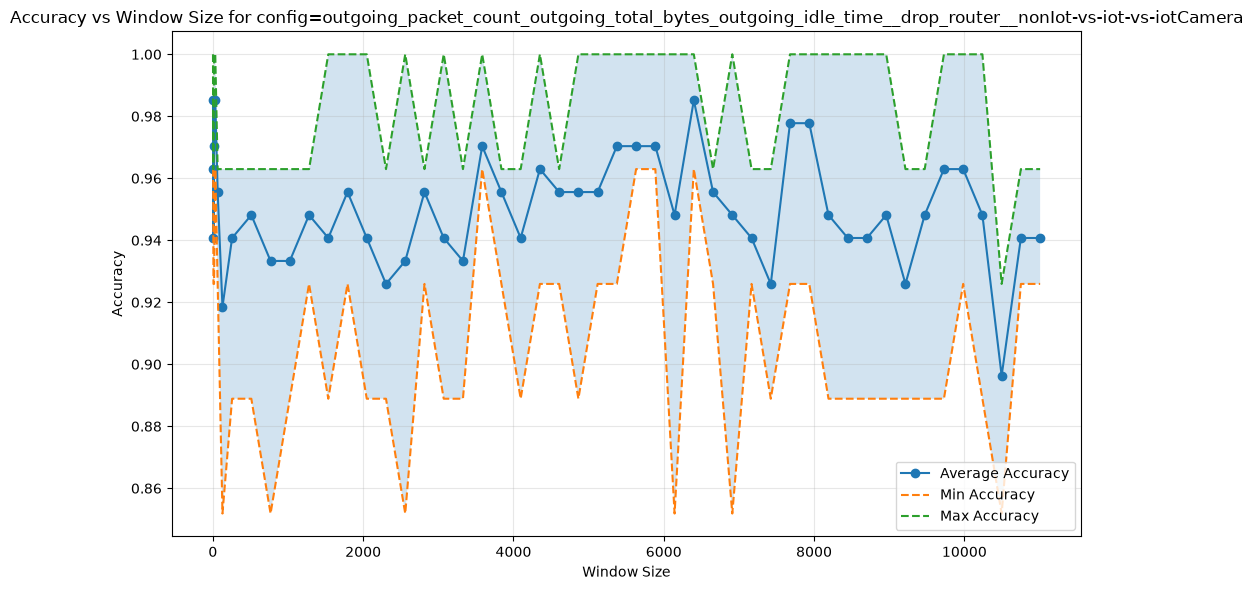

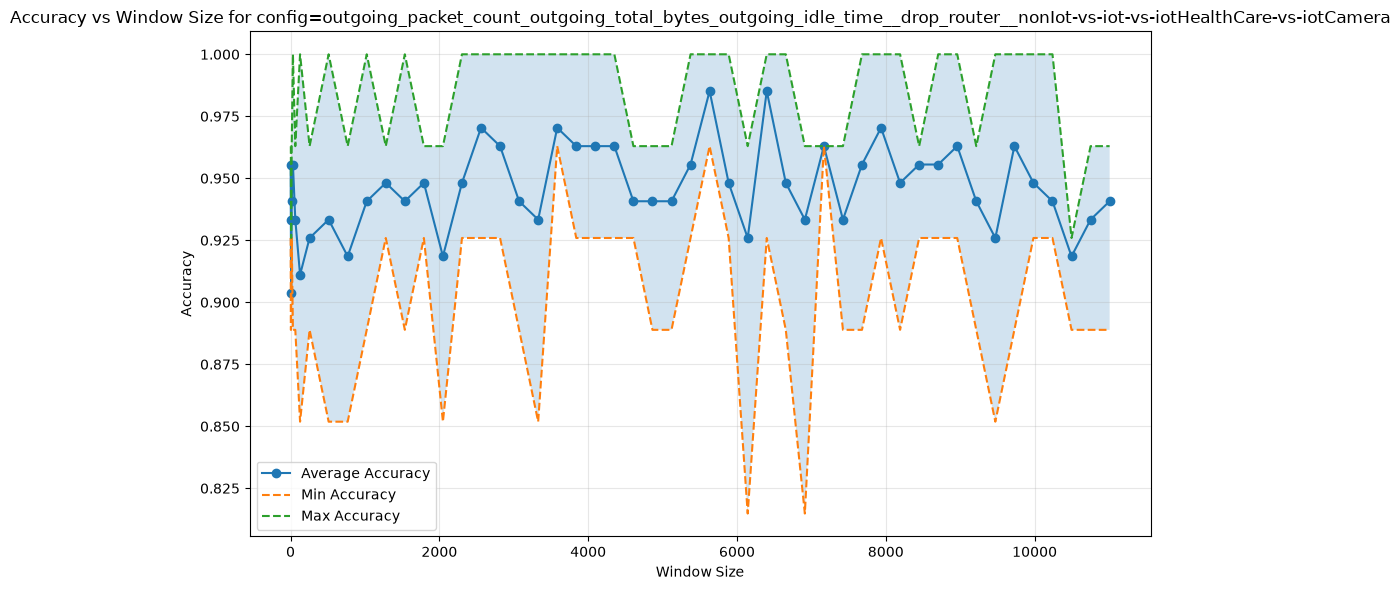

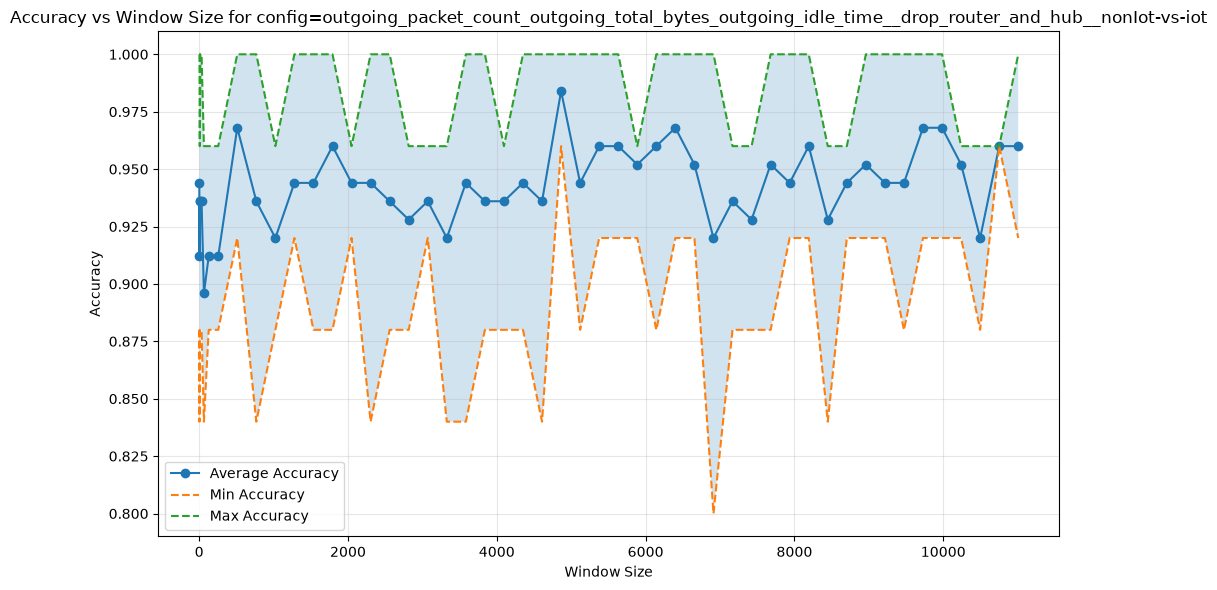

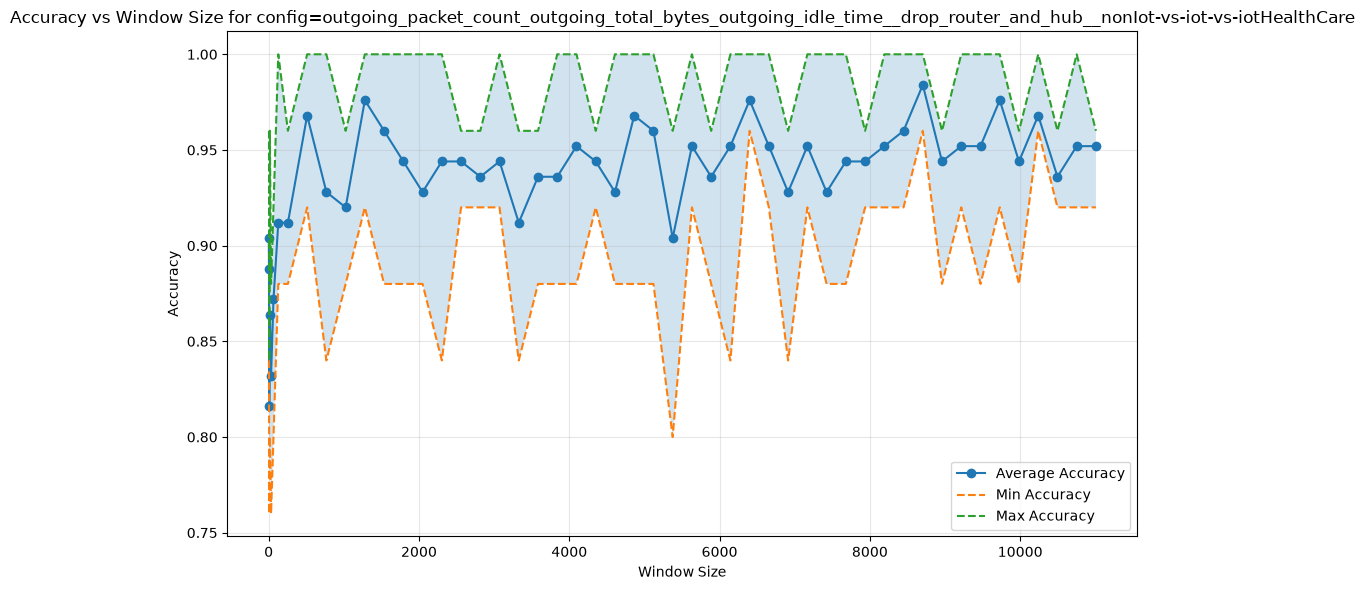

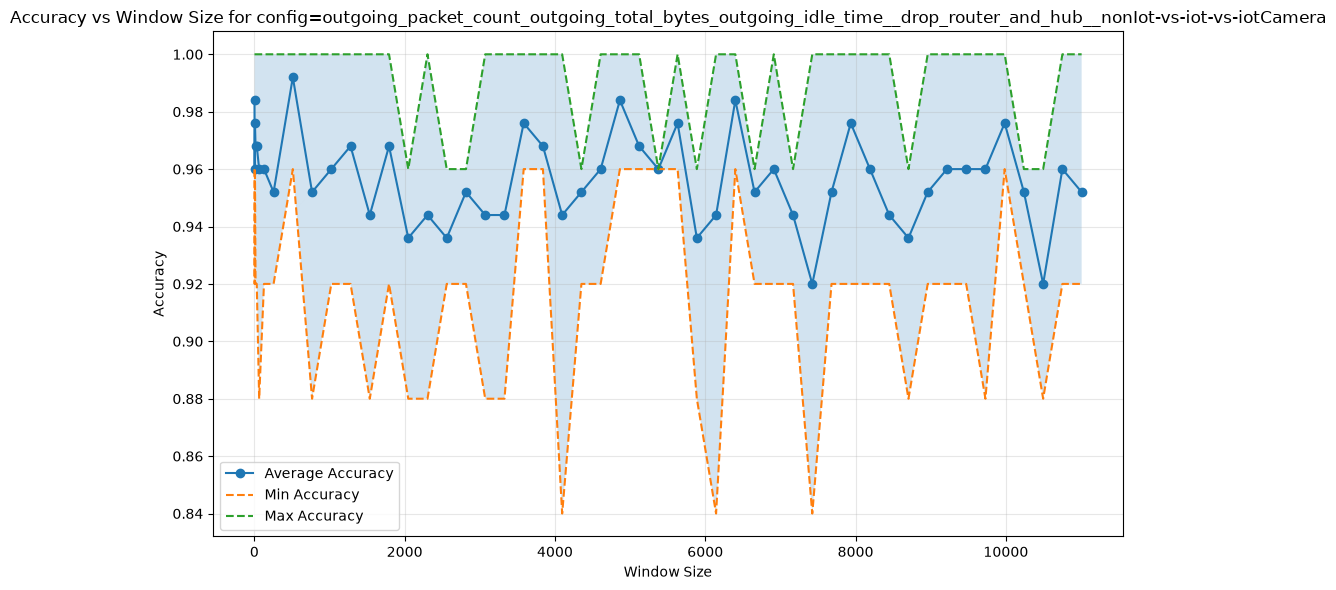

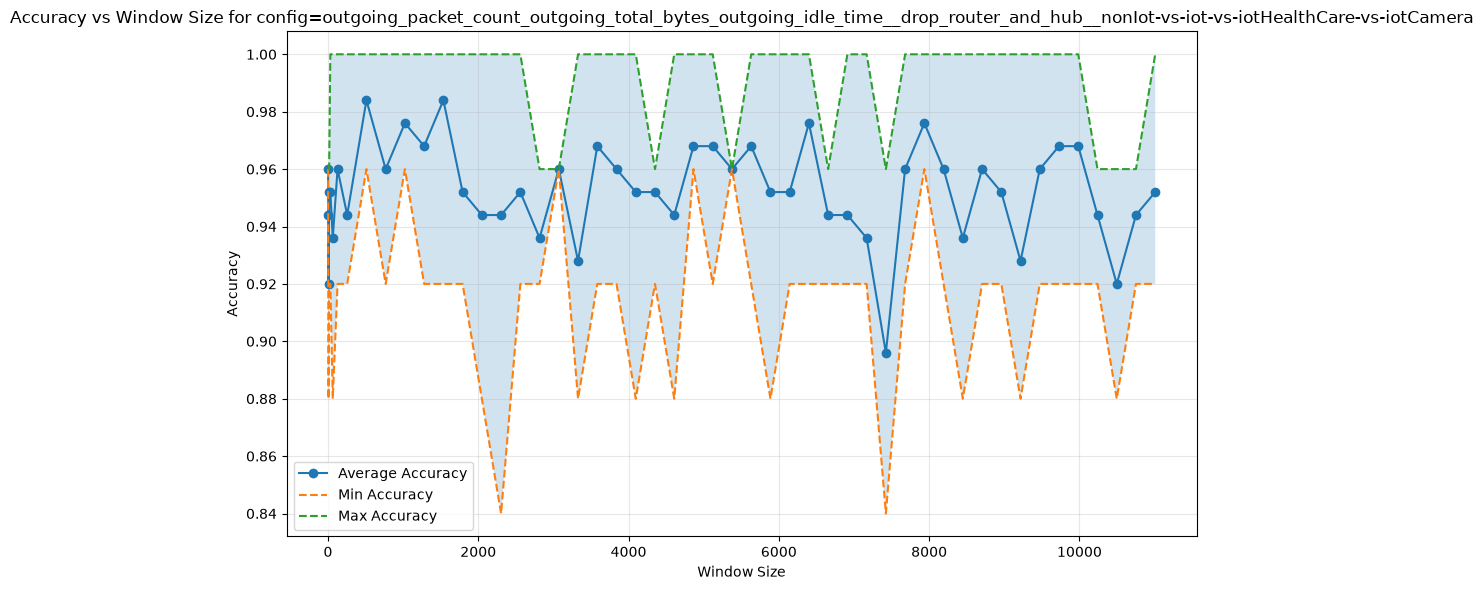

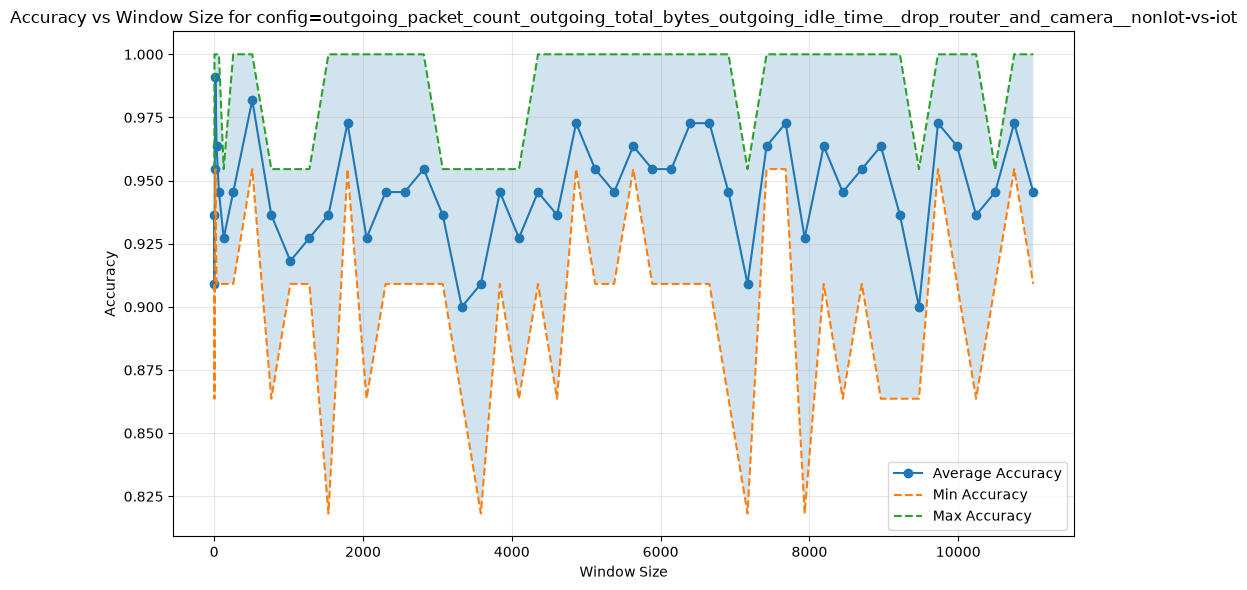

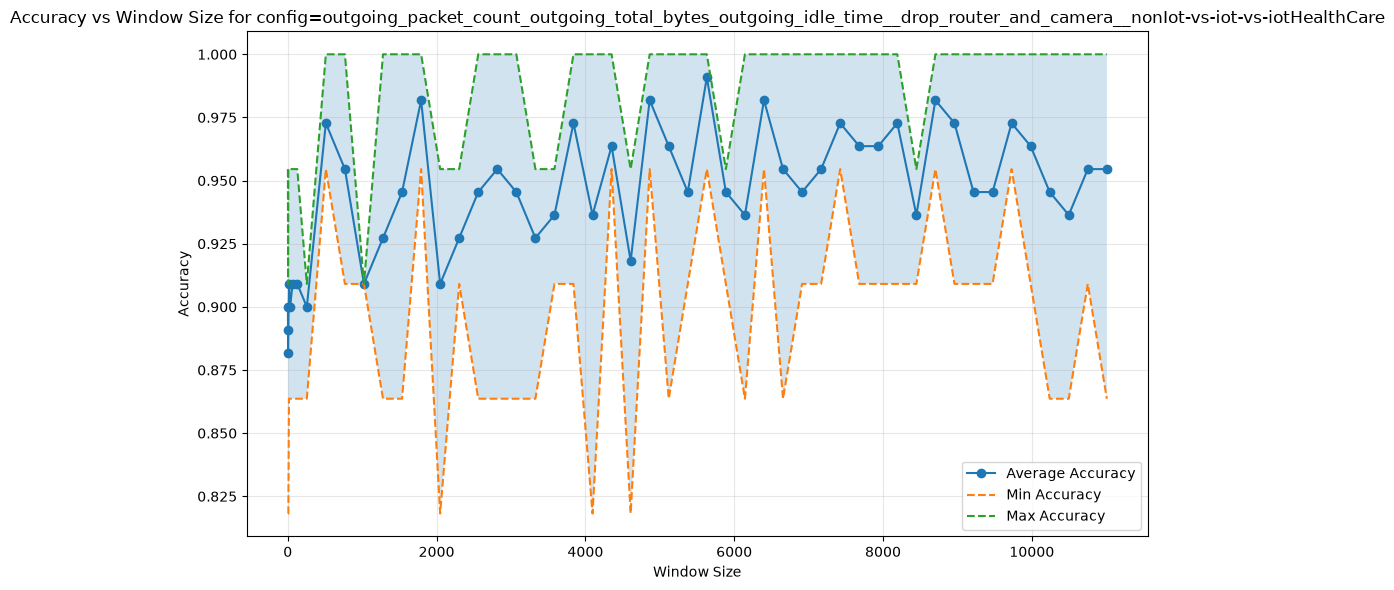

In [31]:
for config in all_configs:
    config_path = PERFORMANCE_EXPORT_FOLDER + "/" + config
    Path(config_path).mkdir(parents=True, exist_ok=True)
    metrics_df = pd.DataFrame(all_configs[config]["metrics"])
    evaluations_df = pd.concat(all_configs[config]["evaluations"])

    # Write these two config into csv files
    metrics_df.to_csv(f"{config_path}/performance.csv", index=False)
    evaluations_df.to_csv(f"{config_path}/detail_performance.csv", index=False)
    with open(f"{config_path}/config.json", "w") as f:
        json.dump(
            all_configs[config]["config"],
            f,
            indent=4
        )

    accuracy_summary = (
        metrics_df
        .groupby("window")["accuracy"]
        .agg(
            avg_accuracy="mean",
            min_accuracy="min",
            max_accuracy="max"
        )
        .reset_index()
        .sort_values("window")
    )

    plt.figure(figsize=(10, 6))

    # Average accuracy
    plt.plot(
        accuracy_summary["window"],
        accuracy_summary["avg_accuracy"],
        marker="o",
        label="Average Accuracy"
    )

    # Min / Max accuracy
    plt.plot(
        accuracy_summary["window"],
        accuracy_summary["min_accuracy"],
        linestyle="--",
        label="Min Accuracy"
    )

    plt.plot(
        accuracy_summary["window"],
        accuracy_summary["max_accuracy"],
        linestyle="--",
        label="Max Accuracy"
    )

    # Shade the min-max range
    plt.fill_between(
        accuracy_summary["window"],
        accuracy_summary["min_accuracy"],
        accuracy_summary["max_accuracy"],
        alpha=0.2
    )

    plt.xlabel("Window Size")
    plt.ylabel("Accuracy")
    plt.title(f"Accuracy vs Window Size for config={config}")
    
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plot_path = f"{config_path}/accuracy_vs_window_size.png"
    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plot_confusion_matrices(
        evaluations_df,
        config_path,
        class_labels=all_configs[config]["config"]["class_labels"]
    )
